Patients with >=3 blood draws: 124
Strong increase: selected 4 patients
Strong decrease: selected 4 patients
Transient peak then drop: selected 4 patients
Rebound/fluctuating: selected 4 patients
Persistent high: selected 1 patients
Stable low: selected 3 patients

Final number of selected patients: 20

========== Final selected trajectory categories ==========
Strong increase             4
Strong decrease             4
Transient peak then drop    4
Rebound/fluctuating         4
Persistent high             1
Stable low                  3
Name: Trajectory_category, dtype: int64

========== Selected representative patients ==========
Patient_Identifier      Trajectory_category  n_draws  baseline_TF  final_TF  max_TF  range_TF     Histological_subtype Molecular_subtype
              AOFA          Strong increase        3        3.753    61.170  61.170    57.417                   Ductal         HR+/HER2-
              ANGM          Strong increase        6       19.200    51.690  59.130   

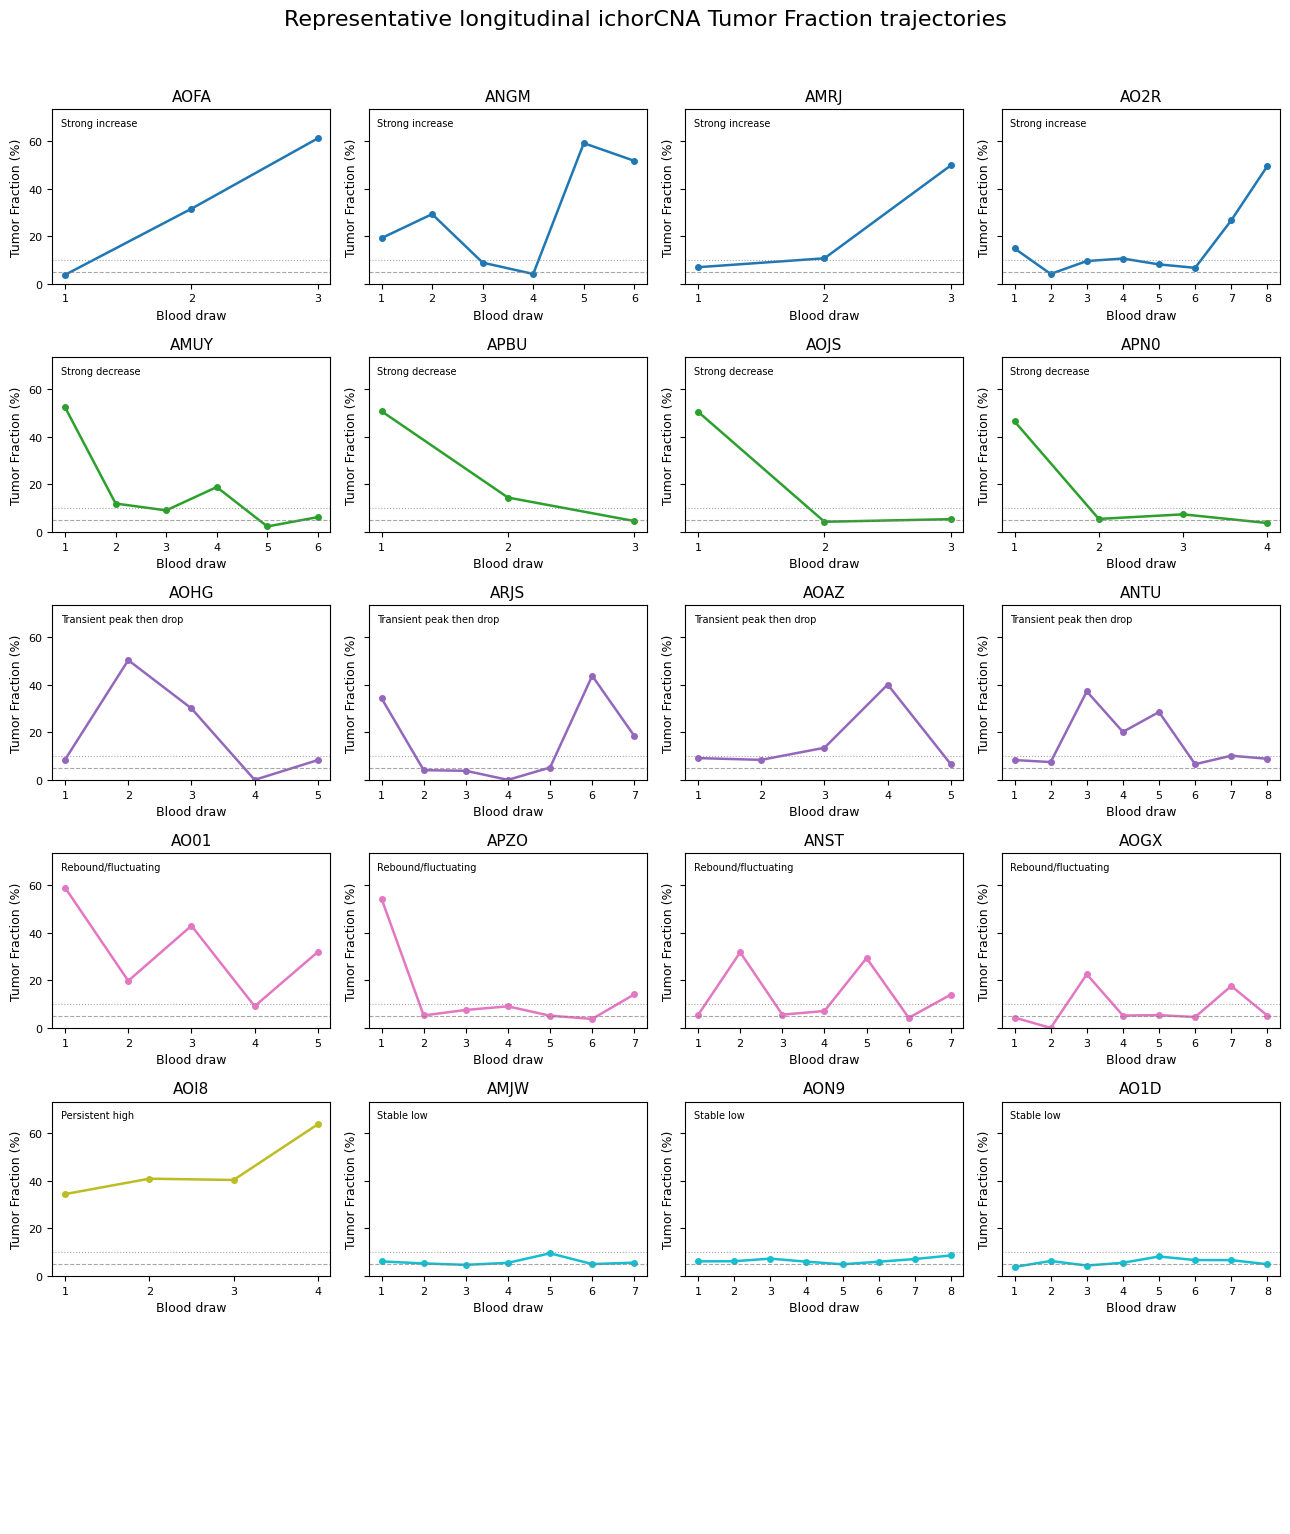


Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Representative_longitudinal_TF_trajectories.png
Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Representative_longitudinal_TF_trajectories.pdf


In [1]:
# ============================================================
# Select and Plot Representative Longitudinal Tumor Fraction Trajectories
# from AURORA shWGS Patients Using ichorCNA Metrics
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math

# ============================================================
# Input file
# ============================================================
input_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.xlsx"
)

out_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot"
)

out_dir.mkdir(parents=True, exist_ok=True)
# ============================================================
# Column names
# ============================================================
patient_col = "Patient_Identifier"
tf_col = "Tumor_Fraction"

histology_col = "Histological_subtype"
subtype_col = "Molecular_subtype"

subclonal_cols = [
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal"
]

date_col = None

# ============================================================
# Load data
# ============================================================
df = pd.read_excel(input_file)

# Keep original row order
df = df.reset_index().rename(columns={"index": "_original_row_order"})

# ============================================================
# Basic checks
# ============================================================
required_cols = [patient_col, tf_col] + subclonal_cols
missing_cols = [c for c in required_cols if c not in df.columns]

if len(missing_cols) > 0:
    raise ValueError(f"Missing required columns: {missing_cols}")

# ============================================================
# Clean patient column
# ============================================================
def clean_text(x):
    if pd.isna(x):
        return pd.NA
    
    x = str(x).strip()
    
    if x in ["", "NA", "N/A", "nan", "NaN", "None", "Missing", "missing"]:
        return pd.NA
    
    return x

df[patient_col] = df[patient_col].apply(clean_text)

# Convert numeric columns
numeric_cols = [tf_col, "Ploidy"] + subclonal_cols

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without patient or tumor fraction
df = df.dropna(subset=[patient_col, tf_col]).copy()

# ============================================================
# Convert Tumor_Fraction to percentage if stored as decimal
# Example: 0.071 -> 7.1%
# ============================================================
if df[tf_col].quantile(0.99) <= 1.5:
    df["Tumor_Fraction_percent"] = df[tf_col] * 100
else:
    df["Tumor_Fraction_percent"] = df[tf_col]

# ============================================================
# Sort samples within patient
# ============================================================
if date_col is not None and date_col in df.columns:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.sort_values([patient_col, date_col, "_original_row_order"])
else:
    df = df.sort_values([patient_col, "_original_row_order"])

df["Blood_Draw_Order"] = df.groupby(patient_col).cumcount() + 1

# ============================================================
# Helper functions for longitudinal patterns
# ============================================================
def count_direction_changes(values, min_change=2.0):
    """
    Count direction changes in TF trajectory.
    Small changes below min_change percentage points are ignored.
    """
    values = np.asarray(values, dtype=float)
    diffs = np.diff(values)

    diffs = diffs[np.abs(diffs) >= min_change]

    if len(diffs) < 2:
        return 0

    signs = np.sign(diffs)
    return int(np.sum(signs[1:] != signs[:-1]))


def has_middle_peak(values):
    """
    True if the highest TF occurs at an internal blood draw,
    not first or last.
    """
    values = np.asarray(values, dtype=float)

    if len(values) < 3:
        return False

    peak_idx = int(np.argmax(values))
    return peak_idx not in [0, len(values) - 1]


def has_middle_trough(values):
    """
    True if the lowest TF occurs at an internal blood draw,
    suggesting rebound/fluctuation.
    """
    values = np.asarray(values, dtype=float)

    if len(values) < 3:
        return False

    trough_idx = int(np.argmin(values))
    return trough_idx not in [0, len(values) - 1]


def first_non_missing_value(x):
    x = pd.Series(x).dropna().astype(str)
    x = x[~x.isin(["Missing", "Unknown", "nan", "None", "NA", "N/A"])]

    if len(x) == 0:
        return "Unknown"

    return x.iloc[0]


# ============================================================
# Build patient-level longitudinal summary
# ============================================================
patient_rows = []

for pid, g in df.groupby(patient_col, sort=False):

    g = g.sort_values("Blood_Draw_Order")
    tf_values = g["Tumor_Fraction_percent"].to_numpy()

    # Use only patients with at least 3 blood draws
    if len(tf_values) < 3:
        continue

    row = {
        patient_col: pid,
        "n_draws": len(tf_values),
        "baseline_TF": tf_values[0],
        "final_TF": tf_values[-1],
        "min_TF": np.nanmin(tf_values),
        "max_TF": np.nanmax(tf_values),
        "mean_TF": np.nanmean(tf_values),
        "median_TF": np.nanmedian(tf_values),
        "range_TF": np.nanmax(tf_values) - np.nanmin(tf_values),
        "delta_final_baseline": tf_values[-1] - tf_values[0],
        "abs_delta_final_baseline": abs(tf_values[-1] - tf_values[0]),
        "direction_changes": count_direction_changes(tf_values),
        "middle_peak": has_middle_peak(tf_values),
        "middle_trough": has_middle_trough(tf_values),
    }

    if histology_col in g.columns:
        row[histology_col] = first_non_missing_value(g[histology_col])

    if subtype_col in g.columns:
        row[subtype_col] = first_non_missing_value(g[subtype_col])

    # Max subclonal metrics per patient
    for col in subclonal_cols:
        row[f"max_{col}"] = g[col].max()
        row[f"mean_{col}"] = g[col].mean()

    patient_rows.append(row)

patient_summary = pd.DataFrame(patient_rows)

print("Patients with >=3 blood draws:", patient_summary.shape[0])

# ============================================================
# Subclonal/CNA complexity score
# Higher score = higher ichorCNA-derived subclonal/CNA complexity
# ============================================================
z_cols = []

for col in subclonal_cols:
    max_col = f"max_{col}"
    z_col = f"z_{max_col}"

    mean_val = patient_summary[max_col].mean()
    std_val = patient_summary[max_col].std(ddof=0)

    if std_val == 0 or pd.isna(std_val):
        patient_summary[z_col] = 0
    else:
        patient_summary[z_col] = (
            patient_summary[max_col] - mean_val
        ) / std_val

    z_cols.append(z_col)

patient_summary["subclonal_complexity_score"] = patient_summary[z_cols].mean(axis=1)

# ============================================================
# Select representative patients using fixed categories
# ============================================================
selected_rows = []
used_patients = set()

def add_category(category_name, pool, n, sort_by, ascending):
    """
    Add top n patients from pool after excluding already selected patients.
    """
    global selected_rows, used_patients

    pool = pool.copy()
    pool = pool[~pool[patient_col].isin(used_patients)]

    if pool.shape[0] == 0:
        print(f"No patients found for category: {category_name}")
        return

    pool = pool.sort_values(sort_by, ascending=ascending)
    chosen = pool.head(n).copy()
    chosen["Trajectory_category"] = category_name

    for _, row in chosen.iterrows():
        used_patients.add(row[patient_col])
        selected_rows.append(row)

    print(f"{category_name}: selected {chosen.shape[0]} patients")


# ------------------------------------------------------------
# Category 1: Strong increase
# final TF - baseline TF >= 15 percentage points
# ------------------------------------------------------------
pool = patient_summary[
    (patient_summary["delta_final_baseline"] >= 15) &
    (patient_summary["max_TF"] >= 10)
]

add_category(
    category_name="Strong increase",
    pool=pool,
    n=4,
    sort_by=["delta_final_baseline", "max_TF"],
    ascending=[False, False]
)

# ------------------------------------------------------------
# Category 2: Strong decrease
# baseline TF - final TF >= 15 percentage points
# ------------------------------------------------------------
pool = patient_summary[
    (patient_summary["delta_final_baseline"] <= -15) &
    (patient_summary["baseline_TF"] >= 10)
]

add_category(
    category_name="Strong decrease",
    pool=pool,
    n=4,
    sort_by=["delta_final_baseline", "baseline_TF"],
    ascending=[True, False]
)

# ------------------------------------------------------------
# Category 3: Transient peak then drop
# internal peak, followed by >=15 percentage point drop
# ------------------------------------------------------------
pool = patient_summary[
    (patient_summary["middle_peak"] == True) &
    ((patient_summary["max_TF"] - patient_summary["final_TF"]) >= 15) &
    (patient_summary["max_TF"] >= 10)
]

add_category(
    category_name="Transient peak then drop",
    pool=pool,
    n=4,
    sort_by=["range_TF", "max_TF"],
    ascending=[False, False]
)

# ------------------------------------------------------------
# Category 4: Rebound / fluctuating
# direction changes or internal trough, with large TF range
# ------------------------------------------------------------
pool = patient_summary[
    (
        (patient_summary["direction_changes"] >= 1) |
        (patient_summary["middle_trough"] == True)
    ) &
    (patient_summary["range_TF"] >= 15) &
    (patient_summary["max_TF"] >= 10)
]

add_category(
    category_name="Rebound/fluctuating",
    pool=pool,
    n=4,
    sort_by=["direction_changes", "range_TF", "max_TF"],
    ascending=[False, False, False]
)

# ------------------------------------------------------------
# Category 5: Persistent high TF
# Consistently elevated TF without a major low-TF dip
# ------------------------------------------------------------

# Ratio of lowest TF to median TF
# Helps exclude cases like 60 -> 20 -> 70
patient_summary["min_to_median_TF_ratio"] = (
    patient_summary["min_TF"] / patient_summary["median_TF"]
)

pool = patient_summary[
    (patient_summary["median_TF"] >= 30) &
    (patient_summary["min_TF"] >= 20) &
    (patient_summary["min_to_median_TF_ratio"] >= 0.70)
]

add_category(
    category_name="Persistent high",
    pool=pool,
    n=3,
    sort_by=["median_TF", "min_TF", "min_to_median_TF_ratio"],
    ascending=[False, False, False]
)

# ------------------------------------------------------------
# Category 6: Stable low TF
# persistently low tumor fraction
# ------------------------------------------------------------
pool = patient_summary[
    (patient_summary["max_TF"] < 10) &
    (patient_summary["range_TF"] < 5)
]

add_category(
    category_name="Stable low",
    pool=pool,
    n=3,
    sort_by=["n_draws", "range_TF"],
    ascending=[False, True]
)

# ============================================================
# Convert selected rows to dataframe
# ============================================================
selected_patients = pd.DataFrame(selected_rows)

if selected_patients.empty:
    raise ValueError("No representative patients were selected. Please check category rules.")

# ============================================================
# Keep only predefined longitudinal TF trajectory categories
# No filler cases
# Plot limit: 5 rows x 4 columns = 20 panels
# ============================================================

allowed_categories = [
    "Strong increase",
    "Strong decrease",
    "Transient peak then drop",
    "Rebound/fluctuating",
    "Persistent high",
    "Stable low"
]

# Maximum number of cases to show per category
category_caps = {
    "Strong increase": 4,
    "Strong decrease": 4,
    "Transient peak then drop": 4,
    "Rebound/fluctuating": 4,
    "Persistent high": 4,
    "Stable low": 4
}

# Keep only selected biological categories
selected_patients = selected_patients[
    selected_patients["Trajectory_category"].isin(allowed_categories)
].copy()

# Set category order
selected_patients["Trajectory_category"] = pd.Categorical(
    selected_patients["Trajectory_category"],
    categories=allowed_categories,
    ordered=True
)

# Sort first by category and then by max TF
selected_patients = selected_patients.sort_values(
    ["Trajectory_category", "max_TF"],
    ascending=[True, False]
).reset_index(drop=True)

# Apply category-specific caps
selected_patients = (
    selected_patients
    .groupby("Trajectory_category", group_keys=False, observed=True)
    .apply(lambda x: x.head(category_caps[str(x.name)]))
    .reset_index(drop=True)
)

# Final hard cap at 24 panels
selected_patients = selected_patients.head(24).copy()

print("\nFinal number of selected patients:", selected_patients.shape[0])

print("\n========== Final selected trajectory categories ==========")
print(
    selected_patients["Trajectory_category"]
    .value_counts()
    .reindex(allowed_categories)
    .dropna()
)

# ============================================================
# Save selected patient summary
# ============================================================
selected_file = out_dir / "Selected_representative_patients.csv"

selected_patients.to_csv(selected_file, index=False)

print("\n========== Selected representative patients ==========")

cols_to_print = [
    patient_col,
    "Trajectory_category",
    "n_draws",
    "baseline_TF",
    "final_TF",
    "max_TF",
    "range_TF",
]

if histology_col in selected_patients.columns:
    cols_to_print.append(histology_col)

if subtype_col in selected_patients.columns:
    cols_to_print.append(subtype_col)

print(selected_patients[cols_to_print].to_string(index=False))

print(f"\nSaved selected patient table: {selected_file}")

# ============================================================
# Prepare plotting dataframe
# ============================================================
selected_ids = selected_patients[patient_col].tolist()

plot_df = df[df[patient_col].isin(selected_ids)].copy()

plot_df = plot_df.merge(
    selected_patients[[patient_col, "Trajectory_category"]],
    on=patient_col,
    how="left"
)

# Preserve selected order
plot_df[patient_col] = pd.Categorical(
    plot_df[patient_col],
    categories=selected_ids,
    ordered=True
)

plot_df = plot_df.sort_values([patient_col, "Blood_Draw_Order"])

# ============================================================
# Plot
# ============================================================
n_rows = 6
n_cols = 4
max_panels = n_rows * n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(13, 15),
    sharey=True
)

axes = np.array(axes).reshape(-1)

# Use one color per category
category_order = allowed_categories
cmap = plt.cm.get_cmap("tab10", len(category_order))

category_color = {
    cat: cmap(i)
    for i, cat in enumerate(category_order)
}

ymax = max(25, plot_df["Tumor_Fraction_percent"].max() * 1.15)

for i, pid in enumerate(selected_ids[:max_panels]):

    ax = axes[i]

    g = plot_df[plot_df[patient_col] == pid].sort_values("Blood_Draw_Order")

    category = g["Trajectory_category"].iloc[0]
    color = category_color[category]

    ax.plot(
        g["Blood_Draw_Order"],
        g["Tumor_Fraction_percent"],
        marker="o",
        linewidth=1.8,
        markersize=4,
        color=color
    )

    # Threshold lines
    ax.axhline(5, linestyle="--", linewidth=0.8, color="gray", alpha=0.7)
    ax.axhline(10, linestyle=":", linewidth=0.8, color="gray", alpha=0.7)

    ax.set_title(f"{pid}", fontsize=11)

    ax.set_ylim(0, ymax)
    ax.set_xticks(g["Blood_Draw_Order"])

    ax.set_xlabel("Blood draw", fontsize=9)
    ax.set_ylabel("Tumor Fraction (%)", fontsize=9)

    ax.tick_params(axis="both", labelsize=8)

    # Category label inside each panel
    ax.text(
        0.03,
        0.95,
        category,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=7,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75)
    )

# Turn off unused panels if fewer than 20 patients
for j in range(len(selected_ids), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Representative longitudinal ichorCNA Tumor Fraction trajectories",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

# ============================================================
# Save figure
# ============================================================
png_file = out_dir / "Representative_longitudinal_TF_trajectories.png"
pdf_file = out_dir / "Representative_longitudinal_TF_trajectories.pdf"

plt.savefig(png_file, dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig(pdf_file, bbox_inches="tight", facecolor="white")

plt.show()

print(f"\nSaved PNG: {png_file}")
print(f"Saved PDF: {pdf_file}")

In [4]:
# ============================================================
# Count total rows and unique patients per trajectory group
# ============================================================

print("\n========== Overall selected plotting dataset ==========")
print(f"Total blood-draw/sample rows: {plot_df.shape[0]}")
print(f"Total unique patients/cases: {plot_df[patient_col].nunique()}")

# One row = one blood draw/sample
# Unique cases = unique Patient_Identifier
trajectory_group_counts = (
    plot_df
    .groupby("Trajectory_category", observed=True)
    .agg(
        total_blood_draw_rows=(patient_col, "size"),
        unique_cases=(patient_col, "nunique")
    )
    .reset_index()
)

# Keep same category order
trajectory_group_counts["Trajectory_category"] = pd.Categorical(
    trajectory_group_counts["Trajectory_category"],
    categories=allowed_categories,
    ordered=True
)

trajectory_group_counts = trajectory_group_counts.sort_values("Trajectory_category")

print("\n========== Cases per trajectory category ==========")
print(trajectory_group_counts.to_string(index=False))



========== Overall selected plotting dataset ==========
Total blood-draw/sample rows: 115
Total unique patients/cases: 20

========== Cases per trajectory category ==========
     Trajectory_category  total_blood_draw_rows  unique_cases
         Strong increase                     20             4
         Strong decrease                     16             4
Transient peak then drop                     25             4
     Rebound/fluctuating                     27             4
         Persistent high                      4             1
              Stable low                     23             3


In [13]:
# ============================================================
# Full cohort: distribution of ALL unique cases across
# 6 longitudinal tumor-fraction trajectory categories
# blood draws >=3, could be evaluated for longitudinal trajectory
# ============================================================

print("\n========== Full cohort unique case count ==========")

total_unique_cases = df[patient_col].nunique()

print(f"Total unique cases/patients in full dataset: {total_unique_cases}")

# ------------------------------------------------------------
# Assign trajectory category to every patient in patient_summary
# ------------------------------------------------------------

def assign_trajectory_category(row):

    # 1. Strong increase
    if (
        row["delta_final_baseline"] >= 15 and
        row["max_TF"] >= 10
    ):
        return "Strong increase"

    # 2. Strong decrease
    if (
        row["delta_final_baseline"] <= -15 and
        row["baseline_TF"] >= 10
    ):
        return "Strong decrease"

    # 3. Transient peak then drop
    if (
        row["middle_peak"] == True and
        (row["max_TF"] - row["final_TF"]) >= 15 and
        row["max_TF"] >= 10
    ):
        return "Transient peak then drop"

    # 4. Rebound/fluctuating
    if (
        (
            row["direction_changes"] >= 1 or
            row["middle_trough"] == True
        ) and
        row["range_TF"] >= 15 and
        row["max_TF"] >= 10
    ):
        return "Rebound/fluctuating"

    # 5. Persistent high
    if (
        row["median_TF"] >= 30 and
        row["min_TF"] >= 20 and
        row["min_to_median_TF_ratio"] >= 0.70
    ):
        return "Persistent high"

    # 6. Stable low
    if (
        row["max_TF"] < 10 and
        row["range_TF"] < 5
    ):
        return "Stable low"

    return "Unclassified"


patient_summary["Trajectory_category_all_cases"] = patient_summary.apply(
    assign_trajectory_category,
    axis=1
)

# ------------------------------------------------------------
# Count unique cases per category
# ------------------------------------------------------------

trajectory_order = [
    "Strong increase",
    "Strong decrease",
    "Transient peak then drop",
    "Rebound/fluctuating",
    "Persistent high",
    "Stable low",
    "Unclassified"
]

patient_summary["Trajectory_category_all_cases"] = pd.Categorical(
    patient_summary["Trajectory_category_all_cases"],
    categories=trajectory_order,
    ordered=True
)

full_trajectory_counts = (
    patient_summary
    .groupby("Trajectory_category_all_cases", observed=False)
    .agg(
        unique_cases=(patient_col, "nunique"),
        total_blood_draw_rows=("n_draws", "sum")
    )
    .reset_index()
)

full_trajectory_counts["percent_of_unique_cases"] = (
    full_trajectory_counts["unique_cases"] /
    full_trajectory_counts["unique_cases"].sum() *
    100
).round(1)

print("\n========== Distribution of unique cases across trajectory categories ==========")
print(full_trajectory_counts.to_string(index=False))

print("\n========== Sanity check ==========")
print(
    "Total classified + unclassified unique cases:",
    full_trajectory_counts["unique_cases"].sum()
)

# ============================================================
# Save all Unclassified cases with selected clinical/ichorCNA/fragment columns
# ============================================================

# Columns you want to keep from the original dataframe
cols_to_save = [
    "Collaborator_sample_id",
    "Patient_id",
    "Patient_Identifier",
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype",
    "Mean_coverage",
    "Tumor_Fraction",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

# ------------------------------------------------------------
# Get Patient_Identifiers classified as Unclassified
# ------------------------------------------------------------

unclassified_patient_ids = (
    patient_summary
    .loc[
        patient_summary["Trajectory_category_all_cases"].astype(str) == "Unclassified",
        patient_col
    ]
    .dropna()
    .unique()
)

print("\n========== Unclassified trajectory cases ==========")
print(f"Number of unique Unclassified patients: {len(unclassified_patient_ids)}")

# ------------------------------------------------------------
# Pull all original rows/blood draws for those patients
# ------------------------------------------------------------

unclassified_df = df[
    df[patient_col].isin(unclassified_patient_ids)
].copy()

print(f"Total blood-draw/sample rows from Unclassified patients: {unclassified_df.shape[0]}")

# ------------------------------------------------------------
# Check requested columns
# ------------------------------------------------------------

missing_cols = [c for c in cols_to_save if c not in unclassified_df.columns]
available_cols = [c for c in cols_to_save if c in unclassified_df.columns]

if len(missing_cols) > 0:
    print("\nWARNING: These requested columns were not found and will be skipped:")
    for c in missing_cols:
        print(f"  - {c}")

# Keep only available requested columns
unclassified_df_to_save = unclassified_df[available_cols].copy()

# Optional: sort nicely by patient and blood draw order
sort_cols = []

if "Patient_Identifier" in unclassified_df_to_save.columns:
    sort_cols.append("Patient_Identifier")

if "Blood_Draw_Order" in unclassified_df.columns:
    unclassified_df_to_save["Blood_Draw_Order"] = unclassified_df["Blood_Draw_Order"]
    sort_cols.append("Blood_Draw_Order")

if len(sort_cols) > 0:
    unclassified_df_to_save = unclassified_df_to_save.sort_values(sort_cols)

# ------------------------------------------------------------
# Save output
# ------------------------------------------------------------

unclassified_file = out_dir / "Unclassified_trajectory_cases_selected_columns.csv"

unclassified_df_to_save.to_csv(
    unclassified_file,
    index=False
)

print(f"\nSaved Unclassified cases table: {unclassified_file}")

# ------------------------------------------------------------
# Preview
# ------------------------------------------------------------

print("\n========== Preview of saved Unclassified cases ==========")
print(unclassified_df_to_save.head(10).to_string(index=False))


========== Full cohort unique case count ==========
Total unique cases/patients in full dataset: 262

========== Distribution of unique cases across trajectory categories ==========
Trajectory_category_all_cases  unique_cases  total_blood_draw_rows  percent_of_unique_cases
              Strong increase            15                     64                     12.1
              Strong decrease            24                    104                     19.4
     Transient peak then drop             9                     55                      7.3
          Rebound/fluctuating             3                      9                      2.4
              Persistent high             0                      0                      0.0
                   Stable low            20                     94                     16.1
                 Unclassified            53                    257                     42.7

========== Sanity check ==========
Total classified + unclassified unique cases:

In [14]:
# ============================================================
# Redesign trajectory groups for ONLY patients with >=3 blood draws
# This uses patient_summary, which already contains only eligible cases
# ============================================================

print("\n========== Redesigning trajectory groups for >=3 blood-draw cases only ==========")

# ------------------------------------------------------------
# Make sure min_to_median_TF_ratio exists
# ------------------------------------------------------------

patient_summary["min_to_median_TF_ratio"] = (
    patient_summary["min_TF"] / patient_summary["median_TF"]
)

# Avoid division issue when median_TF is zero
patient_summary.loc[
    patient_summary["median_TF"] == 0,
    "min_to_median_TF_ratio"
] = np.nan

# ------------------------------------------------------------
# New 4-group trajectory classification
# ------------------------------------------------------------

def assign_4group_longitudinal_trajectory(row):
    """
    Broader trajectory grouping for patients with >=3 blood draws.

    Goal:
    - Avoid sparse 6-category structure
    - Include all eligible longitudinal cases
    - Preserve biological interpretation
    """

    # Group 1: Stable low / low-burden
    # Tumor fraction remains low across the trajectory
    if (
        row["max_TF"] < 10 and
        row["range_TF"] < 5
    ):
        return "Stable low / low-burden"

    # Group 2: Increasing / progression-like
    # Final TF meaningfully higher than baseline
    if (
        row["max_TF"] >= 10 and
        row["delta_final_baseline"] >= 5
    ):
        return "Increasing / progression-like"

    # Group 3: Decreasing / response-like
    # Final TF meaningfully lower than baseline
    # OR patient had a high peak followed by drop
    if (
        row["max_TF"] >= 10 and
        (
            row["delta_final_baseline"] <= -5 or
            (row["max_TF"] - row["final_TF"]) >= 10
        )
    ):
        return "Decreasing / response-like"

    # Group 4: Variable / intermediate
    # Elevated or changing TF but not clearly directional
    return "Variable / intermediate"


patient_summary["Trajectory_4group"] = patient_summary.apply(
    assign_4group_longitudinal_trajectory,
    axis=1
)

# ------------------------------------------------------------
# Order categories
# ------------------------------------------------------------

trajectory_4group_order = [
    "Stable low / low-burden",
    "Increasing / progression-like",
    "Decreasing / response-like",
    "Variable / intermediate"
]

patient_summary["Trajectory_4group"] = pd.Categorical(
    patient_summary["Trajectory_4group"],
    categories=trajectory_4group_order,
    ordered=True
)

# ------------------------------------------------------------
# Count distribution
# ------------------------------------------------------------

trajectory_4group_counts = (
    patient_summary
    .groupby("Trajectory_4group", observed=False)
    .agg(
        unique_cases=(patient_col, "nunique"),
        total_blood_draw_rows=("n_draws", "sum"),
        median_n_draws=("n_draws", "median"),
        median_baseline_TF=("baseline_TF", "median"),
        median_final_TF=("final_TF", "median"),
        median_max_TF=("max_TF", "median"),
        median_delta_final_baseline=("delta_final_baseline", "median"),
        median_range_TF=("range_TF", "median")
    )
    .reset_index()
)

trajectory_4group_counts["percent_of_eligible_cases"] = (
    trajectory_4group_counts["unique_cases"] /
    trajectory_4group_counts["unique_cases"].sum() *
    100
).round(1)

print("\n========== 4-group trajectory distribution among >=3 blood-draw cases ==========")
print(trajectory_4group_counts.to_string(index=False))

print("\n========== Sanity check ==========")
print(f"Total trajectory-eligible unique cases: {patient_summary[patient_col].nunique()}")
print(f"Total cases assigned to 4 groups: {trajectory_4group_counts['unique_cases'].sum()}")

# ------------------------------------------------------------
# Save output
# ------------------------------------------------------------
correlation_out_dir = out_dir / "Correlation_Clinical_variables"
correlation_out_dir.mkdir(parents=True, exist_ok=True)

print(f"\nCorrelation analysis output folder:")
print(correlation_out_dir)


trajectory_4group_count_file = (
    correlation_out_dir / "Trajectory_4group_counts_ge3_blood_draws.csv"
)

trajectory_4group_patient_file = (
    correlation_out_dir / "Trajectory_4group_patient_level_ge3_blood_draws.csv"
)

trajectory_4group_counts.to_csv(
    trajectory_4group_count_file,
    index=False
)

patient_summary.to_csv(
    trajectory_4group_patient_file,
    index=False
)

print(f"\nSaved 4-group counts: {trajectory_4group_count_file}")
print(f"Saved patient-level 4-group table: {trajectory_4group_patient_file}")



========== Redesigning trajectory groups for >=3 blood-draw cases only ==========

========== 4-group trajectory distribution among >=3 blood-draw cases ==========
            Trajectory_4group  unique_cases  total_blood_draw_rows  median_n_draws  median_baseline_TF  median_final_TF  median_max_TF  median_delta_final_baseline  median_range_TF  percent_of_eligible_cases
      Stable low / low-burden            20                     94             4.0              5.5815            5.263          7.077                       0.9375           3.4390                       16.1
Increasing / progression-like            26                    117             4.0              6.5255           30.435         32.905                      17.2030          22.8385                       21.0
   Decreasing / response-like            43                    197             4.0             31.4300            6.180         34.670                     -15.8900          28.4560                       34.7
   

In [15]:
# ============================================================
# Analysis 1: Compare the 4 longitudinal trajectory groups with ichorCNA metrics, fragmentomic metrics, clinical variables, 
# receptor status, and molecular subtype using the ≥3 blood-draw cohort.
# Create sample-level Analysis 1 table
# All blood draws from >=3 blood-draw patients with 4-group trajectory label
# ============================================================

analysis1_sample_out_file = (
    correlation_out_dir / "Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

# Get eligible patients from patient_summary
eligible_patient_ids = patient_summary[patient_col].dropna().unique()

# Keep all blood draws from these patients
analysis1_sample_df = df[
    df[patient_col].isin(eligible_patient_ids)
].copy()

# Merge trajectory group from patient_summary
analysis1_sample_df = analysis1_sample_df.merge(
    patient_summary[
        [
            patient_col,
            "Trajectory_4group",
            "n_draws",
            "baseline_TF",
            "final_TF",
            "min_TF",
            "max_TF",
            "mean_TF",
            "median_TF",
            "range_TF",
            "delta_final_baseline"
        ]
    ],
    on=patient_col,
    how="left"
)

# Columns to keep
analysis1_cols = [
    "Collaborator_sample_id",
    "Patient_id",
    "Patient_Identifier",
    "Blood_Draw_Order",
    "Trajectory_4group",
    "n_draws",

    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype",

    "Mean_coverage",
    "Tumor_Fraction",
    "Tumor_Fraction_percent",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",

    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650",

    "baseline_TF",
    "final_TF",
    "min_TF",
    "max_TF",
    "mean_TF",
    "median_TF",
    "range_TF",
    "delta_final_baseline"
]

available_cols = [c for c in analysis1_cols if c in analysis1_sample_df.columns]
missing_cols = [c for c in analysis1_cols if c not in analysis1_sample_df.columns]

if len(missing_cols) > 0:
    print("\nWARNING: These columns are missing and will be skipped:")
    for c in missing_cols:
        print(f"  - {c}")

analysis1_sample_df = analysis1_sample_df[available_cols].copy()

analysis1_sample_df = analysis1_sample_df.sort_values(
    ["Trajectory_4group", "Patient_Identifier", "Blood_Draw_Order"]
)

analysis1_sample_df.to_csv(
    analysis1_sample_out_file,
    index=False
)

print("\n========== Analysis 1 sample-level table saved ==========")
print(f"Saved file: {analysis1_sample_out_file}")
print(f"Total rows / blood draws: {analysis1_sample_df.shape[0]}")
print(f"Total unique patients: {analysis1_sample_df[patient_col].nunique()}")

print("\nTrajectory group distribution in sample-level file:")
print(
    analysis1_sample_df
    .groupby("Trajectory_4group", observed=False)
    .agg(
        unique_cases=(patient_col, "nunique"),
        total_blood_draw_rows=(patient_col, "size")
    )
    .reset_index()
    .to_string(index=False)
)


========== Analysis 1 sample-level table saved ==========
Saved file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv
Total rows / blood draws: 583
Total unique patients: 124

Trajectory group distribution in sample-level file:
            Trajectory_4group  unique_cases  total_blood_draw_rows
      Stable low / low-burden            20                     94
Increasing / progression-like            26                    117
   Decreasing / response-like            43                    197
      Variable / intermediate            35                    175


In [16]:
# ============================================================
# Analysis 1 QC: Check missingness and group distribution
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

analysis1_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

correlation_out_dir = analysis1_file.parent

analysis1_df = pd.read_csv(analysis1_file)

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

print("\n========== Analysis 1 input summary ==========")
print(f"Input file: {analysis1_file}")
print(f"Output folder: {correlation_out_dir}")
print(f"Total rows / blood draws: {analysis1_df.shape[0]}")
print(f"Total unique patients: {analysis1_df[patient_col].nunique()}")

print("\n========== Trajectory group distribution ==========")
print(
    analysis1_df
    .groupby(group_col, observed=False)
    .agg(
        unique_cases=(patient_col, "nunique"),
        total_blood_draw_rows=(patient_col, "size")
    )
    .reset_index()
    .to_string(index=False)
)

# ============================================================
# Variables for Analysis 1
# ============================================================

clinical_vars = [
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype"
]

continuous_vars = [
    "Tumor_Fraction_percent",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

trajectory_summary_vars = [
    "baseline_TF",
    "final_TF",
    "min_TF",
    "max_TF",
    "mean_TF",
    "median_TF",
    "range_TF",
    "delta_final_baseline"
]

all_check_vars = clinical_vars + continuous_vars + trajectory_summary_vars

available_vars = [v for v in all_check_vars if v in analysis1_df.columns]
missing_vars = [v for v in all_check_vars if v not in analysis1_df.columns]

print("\n========== Missing columns check ==========")
if len(missing_vars) == 0:
    print("All requested variables are present.")
else:
    print("These variables are missing:")
    for v in missing_vars:
        print(f"  - {v}")

# ============================================================
# Missingness summary
# ============================================================

missingness_summary = []

for var in available_vars:
    missing_n = analysis1_df[var].isna().sum()
    missing_pct = missing_n / analysis1_df.shape[0] * 100

    missingness_summary.append({
        "variable": var,
        "missing_rows": missing_n,
        "missing_percent": round(missing_pct, 2),
        "nonmissing_rows": analysis1_df[var].notna().sum()
    })

missingness_df = pd.DataFrame(missingness_summary)

print("\n========== Missingness summary ==========")
print(missingness_df.to_string(index=False))


========== Analysis 1 input summary ==========
Input file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv
Output folder: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables
Total rows / blood draws: 583
Total unique patients: 124

========== Trajectory group distribution ==========
            Trajectory_4group  unique_cases  total_blood_draw_rows
   Decreasing / response-like            43                    197
Increasing / progression-like            26                    117
      Stable low / low-burden            20                     94
      Variable / intermediate            35                    175

========== Missing columns check ==========
All requested variables are present.

========== Missingness summary ==========
                    variable  missing_rows  missing_percent  nonmissing_rows
        H

In [17]:
# ============================================================
# Analysis 1A: Patient-level clinical/receptor association
# across 4 trajectory groups
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import chi2_contingency, fisher_exact

# ------------------------------------------------------------
# Input/output
# ------------------------------------------------------------

analysis1_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1_sample_level_all_draws_ge3_patients_with_Trajectory_4group.csv"
)

correlation_out_dir = analysis1_file.parent

analysis1_df = pd.read_csv(analysis1_file)

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

# ------------------------------------------------------------
# Variables to test at patient level
# ------------------------------------------------------------

clinical_vars = [
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype"
]

# ------------------------------------------------------------
# Create one-row-per-patient table
# ------------------------------------------------------------

patient_level_cols = [
    patient_col,
    group_col,
    "n_draws",
    "baseline_TF",
    "final_TF",
    "min_TF",
    "max_TF",
    "mean_TF",
    "median_TF",
    "range_TF",
    "delta_final_baseline"
] + clinical_vars

available_patient_cols = [
    c for c in patient_level_cols
    if c in analysis1_df.columns
]

patient_level_df = (
    analysis1_df[available_patient_cols]
    .drop_duplicates(subset=[patient_col])
    .copy()
)

print("\n========== Patient-level Analysis 1A input ==========")
print(f"Total unique patients: {patient_level_df[patient_col].nunique()}")
print(f"Total rows: {patient_level_df.shape[0]}")

print("\nTrajectory group distribution:")
print(
    patient_level_df
    .groupby(group_col, observed=False)
    .agg(unique_cases=(patient_col, "nunique"))
    .reset_index()
    .to_string(index=False)
)

# Save patient-level input
patient_level_file = correlation_out_dir / "Analysis1A_patient_level_clinical_input.csv"

patient_level_df.to_csv(
    patient_level_file,
    index=False
)

print(f"\nSaved patient-level clinical input: {patient_level_file}")

# ============================================================
# Clinical variable missingness at patient level
# ============================================================

patient_missingness = []

for var in clinical_vars:
    if var not in patient_level_df.columns:
        continue

    missing_n = patient_level_df[var].isna().sum()
    missing_pct = missing_n / patient_level_df.shape[0] * 100

    patient_missingness.append({
        "variable": var,
        "missing_patients": missing_n,
        "missing_percent": round(missing_pct, 2),
        "nonmissing_patients": patient_level_df[var].notna().sum()
    })

patient_missingness_df = pd.DataFrame(patient_missingness)

print("\n========== Patient-level clinical missingness ==========")
print(patient_missingness_df.to_string(index=False))

patient_missingness_file = (
    correlation_out_dir / "Analysis1A_patient_level_clinical_missingness.csv"
)

patient_missingness_df.to_csv(
    patient_missingness_file,
    index=False
)

print(f"\nSaved patient-level missingness: {patient_missingness_file}")

# ============================================================
# Categorical association tests
# Trajectory_4group vs clinical/receptor variables
# ============================================================

association_results = []
all_contingency_tables = []

for var in clinical_vars:

    if var not in patient_level_df.columns:
        print(f"\nSkipping {var}: column not found.")
        continue

    tmp = patient_level_df[[patient_col, group_col, var]].copy()

    # Keep missing as explicit category for descriptive table
    tmp[var] = tmp[var].fillna("Missing").astype(str)

    contingency = pd.crosstab(
        tmp[group_col],
        tmp[var]
    )

    print(f"\n========== Contingency table: {group_col} vs {var} ==========")
    print(contingency.to_string())

    # Save long-format contingency table
    contingency_long = (
        contingency
        .reset_index()
        .melt(
            id_vars=group_col,
            var_name=var,
            value_name="n_patients"
        )
    )

    contingency_long["clinical_variable"] = var

    all_contingency_tables.append(contingency_long)

    # --------------------------------------------------------
    # Statistical test
    # Exclude missing for formal test
    # --------------------------------------------------------

    test_df = patient_level_df[[group_col, var]].dropna().copy()

    test_table = pd.crosstab(
        test_df[group_col],
        test_df[var]
    )

    n_used = int(test_table.values.sum())

    if test_table.shape[0] < 2 or test_table.shape[1] < 2:
        association_results.append({
            "clinical_variable": var,
            "test": "Not tested",
            "n_patients_used": n_used,
            "table_shape": f"{test_table.shape[0]}x{test_table.shape[1]}",
            "p_value": np.nan,
            "min_expected_count": np.nan,
            "note": "Only one category present after removing missing values"
        })
        continue

    # Chi-square test
    chi2, p, dof, expected = chi2_contingency(test_table)

    min_expected = expected.min()

    note = "Chi-square test"
    test_name = "Chi-square"

    # If 2x2 with low expected counts, use Fisher exact
    if test_table.shape == (2, 2) and min_expected < 5:
        oddsratio, fisher_p = fisher_exact(test_table)
        p = fisher_p
        test_name = "Fisher exact"
        note = "2x2 table with low expected counts"

    elif min_expected < 5:
        note = (
            "Chi-square used, but at least one expected count <5; "
            "interpret cautiously"
        )

    association_results.append({
        "clinical_variable": var,
        "test": test_name,
        "n_patients_used": n_used,
        "table_shape": f"{test_table.shape[0]}x{test_table.shape[1]}",
        "p_value": p,
        "min_expected_count": round(float(min_expected), 3),
        "note": note
    })

# Combine and save results
association_results_df = pd.DataFrame(association_results)

association_results_file = (
    correlation_out_dir / "Analysis1A_patient_level_clinical_association_tests.csv"
)

association_results_df.to_csv(
    association_results_file,
    index=False
)

print("\n========== Patient-level clinical association test results ==========")
print(association_results_df.to_string(index=False))

print(f"\nSaved association test results: {association_results_file}")

# Save all contingency tables
if len(all_contingency_tables) > 0:
    all_contingency_df = pd.concat(
        all_contingency_tables,
        ignore_index=True
    )

    contingency_file = (
        correlation_out_dir / "Analysis1A_patient_level_clinical_contingency_tables.csv"
    )

    all_contingency_df.to_csv(
        contingency_file,
        index=False
    )

    print(f"Saved contingency tables: {contingency_file}")


========== Patient-level Analysis 1A input ==========
Total unique patients: 124
Total rows: 124

Trajectory group distribution:
            Trajectory_4group  unique_cases
   Decreasing / response-like            43
Increasing / progression-like            26
      Stable low / low-burden            20
      Variable / intermediate            35

Saved patient-level clinical input: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_patient_level_clinical_input.csv

========== Patient-level clinical missingness ==========
            variable  missing_patients  missing_percent  nonmissing_patients
Histological_subtype                 2             1.61                  122
           ER_Status                 1             0.81                  123
           PR_Status                 1             0.81                  123
         HER2_Status                 4             3.23                  120
   Molecular_subtype        

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Histological_subtype_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Histological_subtype_trajectory_group_100pct_stacked_barplot.pdf


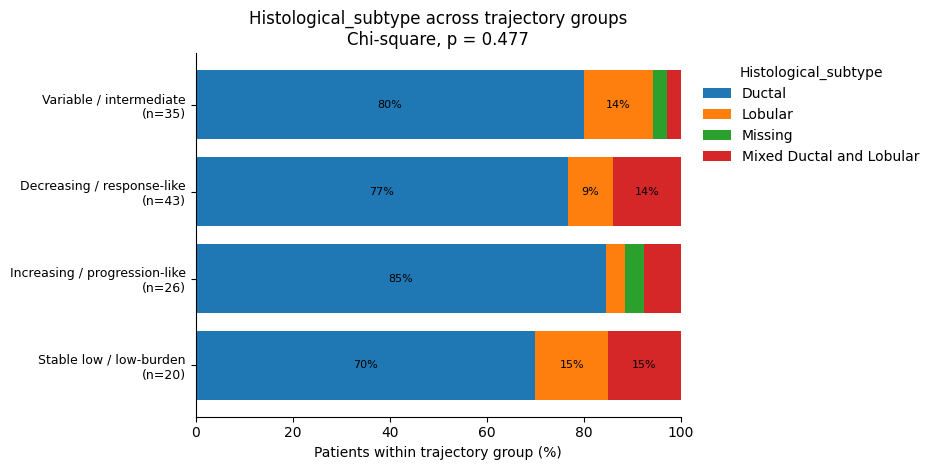

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/ER_Status_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/ER_Status_trajectory_group_100pct_stacked_barplot.pdf


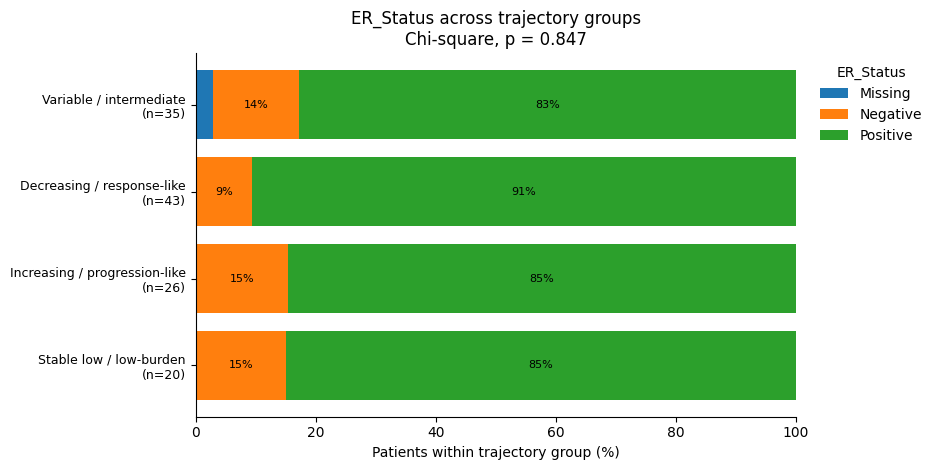

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/PR_Status_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/PR_Status_trajectory_group_100pct_stacked_barplot.pdf


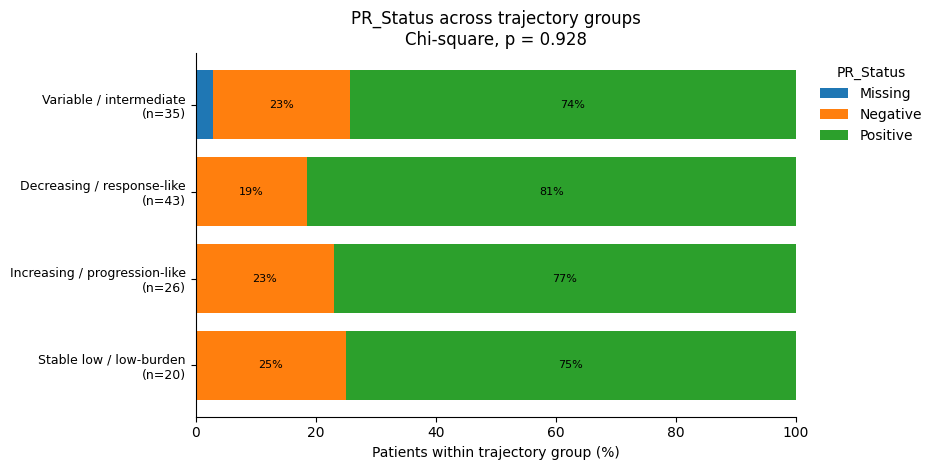

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/HER2_Status_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/HER2_Status_trajectory_group_100pct_stacked_barplot.pdf


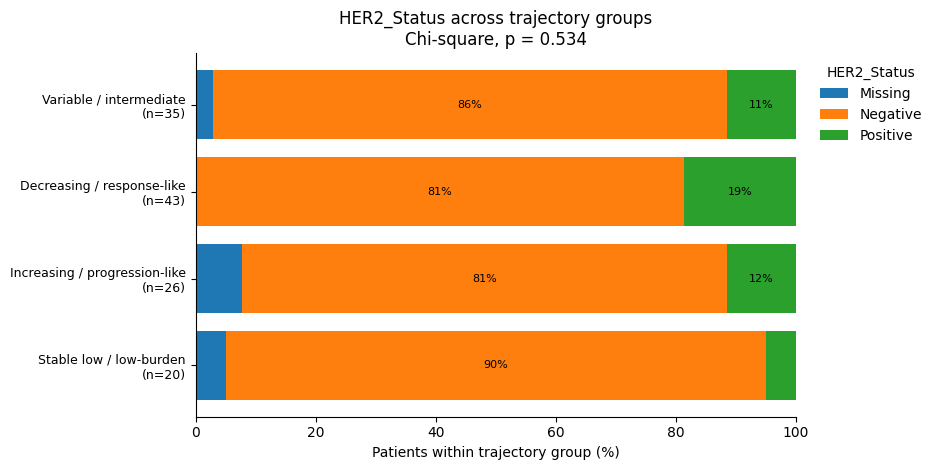

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Molecular_subtype_trajectory_group_100pct_stacked_barplot.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Molecular_subtype_trajectory_group_100pct_stacked_barplot.pdf


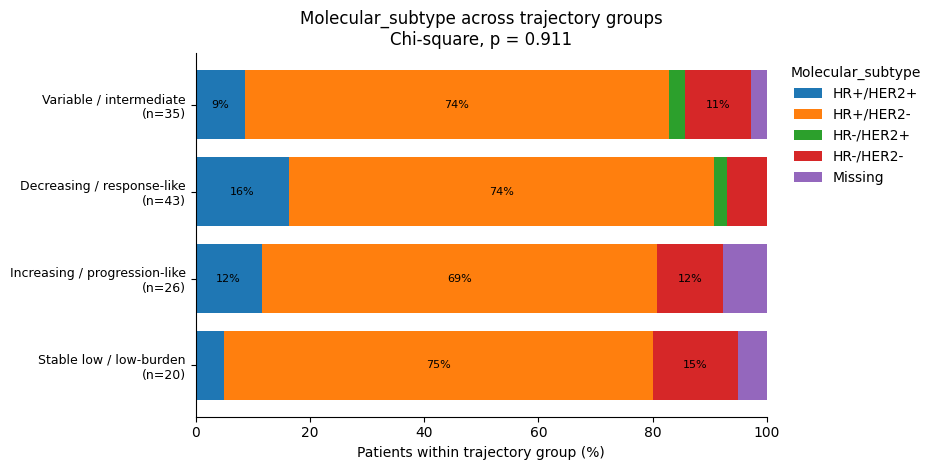


Saved count table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Analysis1A_clinical_composition_counts_long.csv
Saved percent table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Analysis1A_clinical_composition_percentages_long.csv

Saved combined PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis1A_Clinical_composition_plots/Analysis1A_clinical_composition_all_variables_100pct_stacked_barplots.pdf


In [18]:
# ============================================================
# Analysis 1A visualization:
# Clinical/receptor composition across 4 trajectory groups
# 100% stacked bar plots
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages

# ------------------------------------------------------------
# Input/output
# ------------------------------------------------------------

correlation_out_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables"
)

patient_level_file = (
    correlation_out_dir / "Analysis1A_patient_level_clinical_input.csv"
)

association_file = (
    correlation_out_dir / "Analysis1A_patient_level_clinical_association_tests.csv"
)

plot_dir = correlation_out_dir / "Analysis1A_Clinical_composition_plots"
plot_dir.mkdir(parents=True, exist_ok=True)

patient_df = pd.read_csv(patient_level_file)
assoc_df = pd.read_csv(association_file)

patient_col = "Patient_Identifier"
group_col = "Trajectory_4group"

trajectory_order = [
    "Stable low / low-burden",
    "Increasing / progression-like",
    "Decreasing / response-like",
    "Variable / intermediate"
]

clinical_vars = [
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype"
]

# ------------------------------------------------------------
# Clean group order
# ------------------------------------------------------------

patient_df[group_col] = pd.Categorical(
    patient_df[group_col],
    categories=trajectory_order,
    ordered=True
)

# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------

def format_pvalue(p):
    if pd.isna(p):
        return "p = NA"
    elif p < 0.001:
        return "p < 0.001"
    else:
        return f"p = {p:.3f}"


def safe_filename(x):
    return (
        x.replace(" ", "_")
         .replace("/", "_")
         .replace("+", "plus")
         .replace("-", "_")
         .replace(".", "")
    )


def plot_clinical_composition(var, save_single=True):

    tmp = patient_df[[patient_col, group_col, var]].copy()

    # Keep missing visible in descriptive plot
    tmp[var] = tmp[var].fillna("Missing").astype(str)

    # Count table
    count_table = pd.crosstab(
        tmp[group_col],
        tmp[var]
    ).reindex(trajectory_order)

    # Remove empty columns if any
    count_table = count_table.loc[:, count_table.sum(axis=0) > 0]

    # Percent table
    percent_table = count_table.div(
        count_table.sum(axis=1),
        axis=0
    ) * 100

    # Get p-value from association results
    p_row = assoc_df[assoc_df["clinical_variable"] == var]

    if p_row.shape[0] > 0:
        p_text = format_pvalue(p_row["p_value"].iloc[0])
        test_text = str(p_row["test"].iloc[0])
    else:
        p_text = "p = NA"
        test_text = "test not found"

    # Group n labels
    group_n = count_table.sum(axis=1)

    y_labels = [
        f"{g}\n(n={int(group_n.loc[g])})"
        for g in count_table.index
    ]

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(9.5, 4.8))

    left = np.zeros(percent_table.shape[0])

    for category in percent_table.columns:
        values = percent_table[category].values

        bars = ax.barh(
            y=np.arange(percent_table.shape[0]),
            width=values,
            left=left,
            label=category
        )

        # Add labels inside segments if large enough
        for i, val in enumerate(values):
            if val >= 8:
                ax.text(
                    left[i] + val / 2,
                    i,
                    f"{val:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=8
                )

        left += values

    ax.set_yticks(np.arange(percent_table.shape[0]))
    ax.set_yticklabels(y_labels, fontsize=9)

    ax.set_xlim(0, 100)
    ax.set_xlabel("Patients within trajectory group (%)", fontsize=10)

    ax.set_title(
        f"{var} across trajectory groups\n{test_text}, {p_text}",
        fontsize=12
    )

    ax.legend(
        title=var,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    if save_single:
        png_file = plot_dir / f"{safe_filename(var)}_trajectory_group_100pct_stacked_barplot.png"
        pdf_file = plot_dir / f"{safe_filename(var)}_trajectory_group_100pct_stacked_barplot.pdf"

        plt.savefig(
            png_file,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        plt.savefig(
            pdf_file,
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"Saved: {png_file}")
        print(f"Saved: {pdf_file}")

    return fig, count_table, percent_table


# ============================================================
# Generate one plot per clinical variable
# ============================================================

all_count_tables = []
all_percent_tables = []

for var in clinical_vars:

    if var not in patient_df.columns:
        print(f"Skipping {var}: column not found.")
        continue

    fig, count_table, percent_table = plot_clinical_composition(
        var,
        save_single=True
    )

    plt.show()

    # Save long-format count and percent tables
    count_long = (
        count_table
        .reset_index()
        .melt(
            id_vars=group_col,
            var_name="category",
            value_name="n_patients"
        )
    )
    count_long["clinical_variable"] = var

    percent_long = (
        percent_table
        .reset_index()
        .melt(
            id_vars=group_col,
            var_name="category",
            value_name="percent_patients"
        )
    )
    percent_long["clinical_variable"] = var

    all_count_tables.append(count_long)
    all_percent_tables.append(percent_long)


# ============================================================
# Save combined composition tables
# ============================================================

all_counts_df = pd.concat(all_count_tables, ignore_index=True)
all_percents_df = pd.concat(all_percent_tables, ignore_index=True)

count_out_file = plot_dir / "Analysis1A_clinical_composition_counts_long.csv"
percent_out_file = plot_dir / "Analysis1A_clinical_composition_percentages_long.csv"

all_counts_df.to_csv(count_out_file, index=False)
all_percents_df.to_csv(percent_out_file, index=False)

print(f"\nSaved count table: {count_out_file}")
print(f"Saved percent table: {percent_out_file}")


# ============================================================
# Save all plots together into one PDF
# ============================================================

combined_pdf_file = plot_dir / "Analysis1A_clinical_composition_all_variables_100pct_stacked_barplots.pdf"

with PdfPages(combined_pdf_file) as pdf:
    for var in clinical_vars:
        if var not in patient_df.columns:
            continue

        fig, _, _ = plot_clinical_composition(
            var,
            save_single=False
        )

        pdf.savefig(
            fig,
            bbox_inches="tight",
            facecolor="white"
        )

        plt.close(fig)

print(f"\nSaved combined PDF: {combined_pdf_file}")

In [21]:
# ============================================================
# Analysis 2: Paired pre/post-treatment cfDNA analysis
# AURORA ichorCNA + fragmentomics
#
# Goal:
#   Compare cfDNA metrics immediately before treatment vs post-treatment.
#
# Key rule:
#   Exclude patients with only 1 matched blood draw.
#   Keep patients with >=2 blood draws only if a clean pre/post treatment pair exists.
#
# Pre sample:
#   Closest blood draw before treatment start.
#
# Post sample:
#   First blood draw on/after treatment end and before next treatment start.
#
# On-treatment samples:
#   Excluded from paired comparison.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import re

# ============================================================
# 0. User parameters
# ============================================================

# Main cfDNA / ichorCNA / fragmentomics file
cfdna_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.xlsx"
)

# AUP clinical timeline file
aup_clinical_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx"
)

# If running locally with uploaded file, uncomment this:
# aup_clinical_file = Path("/mnt/data/AUP_ClinicalData_20260609.xlsx")

timeline_sheet = "AUP_ClinicalData_20260609.NO.DA"

# Output folder
analysis2_out_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_PrePost_Treatment"
)

analysis2_out_dir.mkdir(parents=True, exist_ok=True)

# Matching columns
cfdna_sample_col = "Collaborator_sample_id"
cfdna_patient_id_col = "Patient_id"
cfdna_patient_identifier_col = "Patient_Identifier"

clinical_patient_col = "patient_id"
clinical_barcode_col = "Barcode"
clinical_category_col = "Category"
clinical_day_col = "Days_From_Primary_Diagnosis"

# Treatment timing columns
treatment_line_col = "Met_Therapy_Line"
regimen_col = "Regimen"
treatment_end_col = "EndTrt_Days_From_Primary_Diagnosis"

# Pair-selection windows
PRE_WINDOW_DAYS = 30
POST_WINDOW_DAYS = 30

# Same-day pre is allowed because blood is often collected before infusion,
# but it will be flagged.
ALLOW_SAME_DAY_PRE = True

# Cleaner primary rule:
# post sample must occur before next treatment start.
REQUIRE_POST_BEFORE_NEXT_TREATMENT = False

# Metrics to compare pre vs post
analysis_metrics = [
    "Tumor_Fraction_percent",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

# Clinical variables to carry into pair table
clinical_annotation_cols = [
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype"
]

# ============================================================
# 1. Helper functions
# ============================================================

def clean_text(x):
    if pd.isna(x):
        return pd.NA

    x = str(x).strip()

    if x in ["", "NA", "N/A", "nan", "NaN", "None", "Missing", "missing"]:
        return pd.NA

    return x


def join_unique_text(x):
    vals = pd.Series(x).dropna().astype(str).str.strip()
    vals = vals[~vals.isin(["", "nan", "NaN", "None", "Missing", "NA", "N/A"])]

    if len(vals) == 0:
        return pd.NA

    return " + ".join(pd.unique(vals))


def first_non_missing(x):
    vals = pd.Series(x).dropna().astype(str).str.strip()
    vals = vals[~vals.isin(["", "nan", "NaN", "None", "Missing", "NA", "N/A"])]

    if len(vals) == 0:
        return pd.NA

    return vals.iloc[0]


def safe_colname(x):
    x = str(x)
    x = x.replace("%", "percent")
    x = re.sub(r"[^A-Za-z0-9]+", "_", x)
    x = re.sub(r"_+", "_", x)
    x = x.strip("_")
    return x


def safe_filename(x):
    x = str(x)
    x = x.replace("/", "_")
    x = x.replace("+", "plus")
    x = re.sub(r"[^A-Za-z0-9_]+", "_", x)
    x = re.sub(r"_+", "_", x)
    x = x.strip("_")
    return x


def bh_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    adjusted = np.full_like(pvalues, np.nan, dtype=float)

    mask = ~np.isnan(pvalues)
    p = pvalues[mask]

    if len(p) == 0:
        return adjusted

    order = np.argsort(p)
    ranked_p = p[order]
    n = len(ranked_p)

    adj = ranked_p * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    adj = np.minimum(adj, 1)

    adjusted_values = np.empty_like(adj)
    adjusted_values[order] = adj

    adjusted[mask] = adjusted_values

    return adjusted


def format_pvalue(p):
    if pd.isna(p):
        return "p = NA"
    if p < 0.001:
        return "p < 0.001"
    return f"p = {p:.3f}"


# ============================================================
# 2. Load cfDNA sample-level data
# ============================================================

print("\n========== Loading cfDNA sample-level file ==========")
print(cfdna_file)

cfdna_df = pd.read_excel(cfdna_file)

print(f"cfDNA rows: {cfdna_df.shape[0]}")
print(f"cfDNA columns: {cfdna_df.shape[1]}")

required_cfdna_cols = [
    cfdna_sample_col,
    cfdna_patient_id_col,
    cfdna_patient_identifier_col,
    "Tumor_Fraction"
]

missing_cfdna_cols = [c for c in required_cfdna_cols if c not in cfdna_df.columns]

if len(missing_cfdna_cols) > 0:
    raise ValueError(f"Missing required cfDNA columns: {missing_cfdna_cols}")

# Clean key columns
cfdna_df[cfdna_sample_col] = cfdna_df[cfdna_sample_col].apply(clean_text)
cfdna_df[cfdna_patient_id_col] = cfdna_df[cfdna_patient_id_col].apply(clean_text)
cfdna_df[cfdna_patient_identifier_col] = cfdna_df[cfdna_patient_identifier_col].apply(clean_text)

cfdna_df["Collaborator_sample_id_clean"] = cfdna_df[cfdna_sample_col].astype(str).str.strip()
cfdna_df["Patient_id_clean"] = cfdna_df[cfdna_patient_id_col].astype(str).str.strip()
cfdna_df["Patient_Identifier_clean"] = cfdna_df[cfdna_patient_identifier_col].astype(str).str.strip()

# Convert numeric columns
numeric_cols = [
    "Tumor_Fraction",
    "Mean_coverage",
    "Ploidy",
    "Subclone Fraction",
    "Frac. Genome Subclonal",
    "Frac. CNA Subclonal",
    "Frac_Subnucleosomal_90_150",
    "Frac_Mononucleosomal_151_250",
    "Frac_Dinucleosomal_251_450",
    "Frac_Trinucleosomal_451_650"
]

for col in numeric_cols:
    if col in cfdna_df.columns:
        cfdna_df[col] = pd.to_numeric(cfdna_df[col], errors="coerce")

# Create Tumor_Fraction_percent if needed
if "Tumor_Fraction_percent" not in cfdna_df.columns:
    if cfdna_df["Tumor_Fraction"].quantile(0.99) <= 1.5:
        cfdna_df["Tumor_Fraction_percent"] = cfdna_df["Tumor_Fraction"] * 100
    else:
        cfdna_df["Tumor_Fraction_percent"] = cfdna_df["Tumor_Fraction"]

# Check duplicate sample IDs
dup_samples = (
    cfdna_df["Collaborator_sample_id_clean"]
    .value_counts()
    .reset_index()
)

dup_samples.columns = ["Collaborator_sample_id_clean", "n_rows"]
dup_samples = dup_samples[dup_samples["n_rows"] > 1]

if dup_samples.shape[0] > 0:
    print("\nWARNING: Duplicate cfDNA sample IDs found.")
    print(dup_samples.head(20).to_string(index=False))

    dup_file = analysis2_out_dir / "Analysis2_QC_duplicate_cfdna_sample_ids.csv"
    dup_samples.to_csv(dup_file, index=False)
    print(f"Saved duplicate sample ID table: {dup_file}")

# For matching, keep first duplicate if present
cfdna_df_for_merge = (
    cfdna_df
    .sort_values(["Collaborator_sample_id_clean"])
    .drop_duplicates(subset=["Collaborator_sample_id_clean"], keep="first")
    .copy()
)

print(f"Unique cfDNA sample IDs for merge: {cfdna_df_for_merge.shape[0]}")


# ============================================================
# 3. Load AUP clinical timeline
# ============================================================

print("\n========== Loading AUP clinical timeline ==========")
print(aup_clinical_file)
print(f"Sheet: {timeline_sheet}")

timeline_df = pd.read_excel(
    aup_clinical_file,
    sheet_name=timeline_sheet
)

print(f"Timeline rows: {timeline_df.shape[0]}")
print(f"Timeline columns: {timeline_df.shape[1]}")

required_timeline_cols = [
    clinical_patient_col,
    clinical_category_col,
    clinical_day_col,
    clinical_barcode_col,
    treatment_line_col,
    regimen_col,
    treatment_end_col
]

missing_timeline_cols = [c for c in required_timeline_cols if c not in timeline_df.columns]

if len(missing_timeline_cols) > 0:
    raise ValueError(f"Missing required clinical timeline columns: {missing_timeline_cols}")

# Clean key columns
timeline_df[clinical_patient_col] = timeline_df[clinical_patient_col].apply(clean_text)
timeline_df[clinical_category_col] = timeline_df[clinical_category_col].apply(clean_text)
timeline_df[clinical_barcode_col] = timeline_df[clinical_barcode_col].apply(clean_text)
timeline_df[treatment_line_col] = timeline_df[treatment_line_col].apply(clean_text)
timeline_df[regimen_col] = timeline_df[regimen_col].apply(clean_text)

timeline_df["patient_id_clean"] = timeline_df[clinical_patient_col].astype(str).str.strip()
timeline_df["Category_clean"] = timeline_df[clinical_category_col].astype(str).str.strip()
timeline_df["Barcode_clean"] = timeline_df[clinical_barcode_col].astype(str).str.strip()

timeline_df[clinical_day_col] = pd.to_numeric(
    timeline_df[clinical_day_col],
    errors="coerce"
)

timeline_df[treatment_end_col] = pd.to_numeric(
    timeline_df[treatment_end_col],
    errors="coerce"
)


# ============================================================
# 4. Extract blood draws and match to cfDNA metrics
# ============================================================

print("\n========== Extracting blood draw timeline ==========")

blood_draws_raw = timeline_df[
    timeline_df["Category_clean"].eq("Blood_Draw")
].copy()

blood_draws_raw = blood_draws_raw[
    blood_draws_raw["Barcode_clean"].notna()
].copy()

blood_draws_raw = blood_draws_raw.rename(
    columns={
        clinical_day_col: "draw_day"
    }
)

blood_draws_raw["Patient_Identifier_from_Barcode"] = (
    blood_draws_raw["Barcode_clean"]
    .astype(str)
    .str.replace(r"-NB.*$", "", regex=True)
)

print(f"Blood draw rows in clinical timeline with Barcode: {blood_draws_raw.shape[0]}")
print(f"Unique patients in blood draw timeline: {blood_draws_raw['patient_id_clean'].nunique()}")

# Merge blood draw timeline with cfDNA metrics
blood_draws_merged = blood_draws_raw.merge(
    cfdna_df_for_merge,
    left_on="Barcode_clean",
    right_on="Collaborator_sample_id_clean",
    how="left",
    indicator="_cfDNA_merge_status"
)

# Save all blood draws with cfDNA merge status
blood_draws_all_file = (
    analysis2_out_dir / "Analysis2_blood_draw_timeline_all_with_cfDNA_merge_status.csv"
)

blood_draws_merged.to_csv(
    blood_draws_all_file,
    index=False
)

print(f"Saved blood draw timeline with merge status: {blood_draws_all_file}")

# QC unmatched blood draws
unmatched_blood_draws = blood_draws_merged[
    blood_draws_merged["_cfDNA_merge_status"].ne("both")
].copy()

unmatched_blood_draw_file = (
    analysis2_out_dir / "Analysis2_QC_blood_draws_without_cfDNA_metrics.csv"
)

unmatched_blood_draws.to_csv(
    unmatched_blood_draw_file,
    index=False
)

print(f"Blood draws without cfDNA metrics: {unmatched_blood_draws.shape[0]}")
print(f"Saved unmatched blood draws: {unmatched_blood_draw_file}")

# Keep only blood draws with cfDNA metrics
blood_draws_matched = blood_draws_merged[
    blood_draws_merged["_cfDNA_merge_status"].eq("both")
].copy()

blood_draws_matched = blood_draws_matched.sort_values(
    ["patient_id_clean", "draw_day", "Barcode_clean"]
)

matched_blood_draw_file = (
    analysis2_out_dir / "Analysis2_blood_draw_timeline_matched_cfDNA_metrics.csv"
)

blood_draws_matched.to_csv(
    matched_blood_draw_file,
    index=False
)

print(f"Matched blood draws with cfDNA metrics: {blood_draws_matched.shape[0]}")
print(f"Unique patients with matched cfDNA blood draws: {blood_draws_matched['patient_id_clean'].nunique()}")
print(f"Saved matched blood draw table: {matched_blood_draw_file}")


# ============================================================
# 5. Exclude patients with only 1 matched blood draw
# ============================================================

print("\n========== Analysis 2 blood-draw eligibility ==========")

blood_draw_counts = (
    blood_draws_matched
    .groupby("patient_id_clean")
    .agg(
        n_matched_blood_draws=("Barcode_clean", "nunique"),
        first_draw_day=("draw_day", "min"),
        last_draw_day=("draw_day", "max")
    )
    .reset_index()
)

blood_draw_counts["eligible_ge2_draws"] = (
    blood_draw_counts["n_matched_blood_draws"] >= 2
)

n_total_matched_patients = blood_draw_counts["patient_id_clean"].nunique()
n_one_draw = blood_draw_counts[
    blood_draw_counts["n_matched_blood_draws"] == 1
]["patient_id_clean"].nunique()
n_ge2_draws = blood_draw_counts[
    blood_draw_counts["n_matched_blood_draws"] >= 2
]["patient_id_clean"].nunique()

print(f"Patients with matched cfDNA blood draws: {n_total_matched_patients}")
print(f"Patients with only 1 matched blood draw, excluded: {n_one_draw}")
print(f"Patients with >=2 matched blood draws, eligible for pre/post search: {n_ge2_draws}")

blood_draw_counts_file = (
    analysis2_out_dir / "Analysis2_blood_draw_count_per_patient.csv"
)

blood_draw_counts.to_csv(
    blood_draw_counts_file,
    index=False
)

print(f"Saved blood draw count table: {blood_draw_counts_file}")

eligible_patient_ids_ge2 = (
    blood_draw_counts
    .loc[blood_draw_counts["eligible_ge2_draws"], "patient_id_clean"]
    .tolist()
)

blood_draws_eligible = blood_draws_matched[
    blood_draws_matched["patient_id_clean"].isin(eligible_patient_ids_ge2)
].copy()

eligible_blood_draw_file = (
    analysis2_out_dir / "Analysis2_blood_draw_timeline_ge2_patients_matched_cfDNA_metrics.csv"
)

blood_draws_eligible.to_csv(
    eligible_blood_draw_file,
    index=False
)

print(f"Saved eligible >=2-draw matched blood draws: {eligible_blood_draw_file}")


# ============================================================
# 6. Build metastatic treatment episode table
# ============================================================

print("\n========== Building treatment episode table ==========")

# Treatment rows:
# keep metastatic treatment rows with regimen and a start day.
therapy_raw = timeline_df[
    timeline_df[regimen_col].notna() &
    timeline_df[clinical_day_col].notna() &
    timeline_df["Category_clean"].astype(str).str.startswith("Met_")
].copy()

therapy_raw = therapy_raw.rename(
    columns={
        clinical_day_col: "treatment_start_day",
        treatment_end_col: "treatment_end_day"
    }
)

therapy_raw["Met_Therapy_Line_clean"] = (
    therapy_raw[treatment_line_col]
    .astype(str)
    .str.strip()
    .replace({"<NA>": np.nan, "nan": np.nan, "None": np.nan})
)

therapy_raw["treatment_start_day"] = pd.to_numeric(
    therapy_raw["treatment_start_day"],
    errors="coerce"
)

therapy_raw["treatment_end_day"] = pd.to_numeric(
    therapy_raw["treatment_end_day"],
    errors="coerce"
)

print(f"Raw treatment rows with regimen: {therapy_raw.shape[0]}")
print(f"Unique treated patients: {therapy_raw['patient_id_clean'].nunique()}")

therapy_raw_file = (
    analysis2_out_dir / "Analysis2_treatment_rows_raw.csv"
)

therapy_raw.to_csv(
    therapy_raw_file,
    index=False
)

print(f"Saved raw treatment rows: {therapy_raw_file}")

# Collapse simultaneous combination treatments:
# group by patient, treatment line, and same start day.
# Use max end day as the episode end day to cover full combined regimen exposure.
episode_table = (
    therapy_raw
    .groupby(
        ["patient_id_clean", "Met_Therapy_Line_clean", "treatment_start_day"],
        dropna=False
    )
    .agg(
        patient_id=(clinical_patient_col, first_non_missing),
        treatment_categories=("Category_clean", join_unique_text),
        Met_Therapy_Line=(treatment_line_col, join_unique_text),
        regimen_combined=(regimen_col, join_unique_text),
        treatment_end_day=("treatment_end_day", "max"),
        treatment_end_day_min=("treatment_end_day", "min"),
        Treatment_Response=("Treatment_Response", join_unique_text),
        Progression=("Progression", join_unique_text),
        Reason_Tx_Ended=("Reason_Tx_Ended", join_unique_text),
        n_treatment_components=(regimen_col, "size")
    )
    .reset_index()
)

episode_table = episode_table.sort_values(
    ["patient_id_clean", "treatment_start_day", "treatment_end_day"]
)

episode_table["episode_number_for_patient"] = (
    episode_table
    .groupby("patient_id_clean")
    .cumcount() + 1
)

episode_table["episode_id"] = (
    episode_table["patient_id_clean"].astype(str) +
    "_EP" +
    episode_table["episode_number_for_patient"].astype(str).str.zfill(2)
)

episode_table["next_treatment_start_day"] = (
    episode_table
    .groupby("patient_id_clean")["treatment_start_day"]
    .shift(-1)
)

episode_table["treatment_duration_days"] = (
    episode_table["treatment_end_day"] -
    episode_table["treatment_start_day"]
)

episode_file = (
    analysis2_out_dir / "Analysis2_treatment_episode_table_collapsed.csv"
)

episode_table.to_csv(
    episode_file,
    index=False
)

print(f"Collapsed treatment episodes: {episode_table.shape[0]}")
print(f"Saved treatment episode table: {episode_file}")


# ============================================================
# 7. Select clean pre/post-treatment pairs
# ============================================================

print("\n========== Selecting clean pre/post-treatment pairs ==========")

metric_map = {
    metric: safe_colname(metric)
    for metric in analysis_metrics
    if metric in blood_draws_eligible.columns
}

missing_metrics = [m for m in analysis_metrics if m not in blood_draws_eligible.columns]

if len(missing_metrics) > 0:
    print("\nWARNING: These metrics are missing and will be skipped:")
    for m in missing_metrics:
        print(f"  - {m}")

print("\nMetrics available for paired analysis:")
for m in metric_map:
    print(f"  - {m}")

blood_draws_by_patient = {
    pid: g.sort_values(["draw_day", "Barcode_clean"]).copy()
    for pid, g in blood_draws_eligible.groupby("patient_id_clean")
}

matched_draw_counts_dict = (
    blood_draw_counts
    .set_index("patient_id_clean")["n_matched_blood_draws"]
    .to_dict()
)

pair_rows = []
episode_status_rows = []

for _, ep in episode_table.iterrows():

    pid = ep["patient_id_clean"]
    episode_id = ep["episode_id"]

    start_day = ep["treatment_start_day"]
    end_day = ep["treatment_end_day"]
    next_start_day = ep["next_treatment_start_day"]

    n_draws_patient = matched_draw_counts_dict.get(pid, 0)

    status_row = {
        "episode_id": episode_id,
        "patient_id_clean": pid,
        "patient_id": ep.get("patient_id", pd.NA),
        "Met_Therapy_Line": ep.get("Met_Therapy_Line", pd.NA),
        "regimen_combined": ep.get("regimen_combined", pd.NA),
        "treatment_categories": ep.get("treatment_categories", pd.NA),
        "treatment_start_day": start_day,
        "treatment_end_day": end_day,
        "next_treatment_start_day": next_start_day,
        "n_matched_blood_draws_for_patient": n_draws_patient,
        "pair_status": "Not evaluated",
        "exclusion_reason": pd.NA
    }

    if n_draws_patient < 2:
        status_row["pair_status"] = "Excluded"
        status_row["exclusion_reason"] = "Patient has fewer than 2 matched cfDNA blood draws"
        episode_status_rows.append(status_row)
        continue

    if pid not in blood_draws_by_patient:
        status_row["pair_status"] = "Excluded"
        status_row["exclusion_reason"] = "No matched cfDNA blood draws available after eligibility filter"
        episode_status_rows.append(status_row)
        continue

    if pd.isna(start_day):
        status_row["pair_status"] = "Excluded"
        status_row["exclusion_reason"] = "Missing treatment start day"
        episode_status_rows.append(status_row)
        continue

    if pd.isna(end_day):
        status_row["pair_status"] = "Excluded"
        status_row["exclusion_reason"] = "Missing treatment end day"
        episode_status_rows.append(status_row)
        continue

    g = blood_draws_by_patient[pid].copy()

    # -------------------------
    # Pre-treatment candidates
    # -------------------------
    if ALLOW_SAME_DAY_PRE:
        pre_candidates = g[g["draw_day"] <= start_day].copy()
    else:
        pre_candidates = g[g["draw_day"] < start_day].copy()

    pre_candidates["days_pre_to_start"] = (
        start_day - pre_candidates["draw_day"]
    )

    pre_candidates = pre_candidates[
        pre_candidates["days_pre_to_start"] >= 0
    ].copy()

    if PRE_WINDOW_DAYS is not None:
        pre_candidates = pre_candidates[
            pre_candidates["days_pre_to_start"] <= PRE_WINDOW_DAYS
        ].copy()

    if pre_candidates.shape[0] == 0:
        status_row["pair_status"] = "Excluded"
        status_row["exclusion_reason"] = "No pre-treatment blood draw within pre window"
        episode_status_rows.append(status_row)
        continue

    pre_sample = (
        pre_candidates
        .sort_values(
            ["days_pre_to_start", "draw_day"],
            ascending=[True, False]
        )
        .iloc[0]
    )

    # -------------------------
    # On-treatment samples
    # These are counted but excluded.
    # -------------------------
    on_treatment_candidates = g[
        (g["draw_day"] > start_day) &
        (g["draw_day"] < end_day)
    ].copy()

    n_on_treatment_draws_excluded = on_treatment_candidates.shape[0]

    # -------------------------
    # Post-treatment candidates
    # -------------------------
    post_candidates = g[g["draw_day"] >= end_day].copy()

    post_candidates["days_end_to_post"] = (
        post_candidates["draw_day"] - end_day
    )

    post_candidates = post_candidates[
        post_candidates["days_end_to_post"] >= 0
    ].copy()

    if POST_WINDOW_DAYS is not None:
        post_candidates = post_candidates[
            post_candidates["days_end_to_post"] <= POST_WINDOW_DAYS
        ].copy()
    # ------------------------------------------------------------
    # Flag whether post draw occurs before or after next treatment
    # Do not exclude here if REQUIRE_POST_BEFORE_NEXT_TREATMENT = False
    # ------------------------------------------------------------

    if pd.notna(next_start_day):
        post_candidates["post_before_next_treatment_start"] = (
            post_candidates["draw_day"] < next_start_day
        )

        post_candidates["post_after_next_treatment_start"] = (
            post_candidates["draw_day"] >= next_start_day
        )
    else:
        post_candidates["post_before_next_treatment_start"] = True
        post_candidates["post_after_next_treatment_start"] = False


    # Strict option: require post draw before next treatment
    # Practical option: keep post draw but flag if after next treatment started

    if (
        REQUIRE_POST_BEFORE_NEXT_TREATMENT and
        pd.notna(next_start_day)
    ):
        post_candidates = post_candidates[
            post_candidates["post_before_next_treatment_start"] == True
        ].copy()
    if post_candidates.shape[0] == 0:
        status_row["pair_status"] = "Excluded"
        status_row["exclusion_reason"] = "No clean post-treatment blood draw"
        episode_status_rows.append(status_row)
        continue

    post_sample = (
        post_candidates
        .sort_values(
            ["days_end_to_post", "draw_day"],
            ascending=[True, True]
        )
        .iloc[0]
    )

    # Pre and post must be different samples
    if pre_sample["Barcode_clean"] == post_sample["Barcode_clean"]:
        status_row["pair_status"] = "Excluded"
        status_row["exclusion_reason"] = "Pre and post selected the same blood draw"
        episode_status_rows.append(status_row)
        continue

    # -------------------------
    # Build paired row
    # -------------------------
    pair_row = {
        "episode_id": episode_id,
        "patient_id_clean": pid,
        "patient_id": ep.get("patient_id", pd.NA),
        "Patient_id_from_cfDNA_pre": pre_sample.get(cfdna_patient_id_col, pd.NA),
        "Patient_id_from_cfDNA_post": post_sample.get(cfdna_patient_id_col, pd.NA),
        "Patient_Identifier_pre": pre_sample.get(cfdna_patient_identifier_col, pd.NA),
        "Patient_Identifier_post": post_sample.get(cfdna_patient_identifier_col, pd.NA),

        "Met_Therapy_Line": ep.get("Met_Therapy_Line", pd.NA),
        "regimen_combined": ep.get("regimen_combined", pd.NA),
        "treatment_categories": ep.get("treatment_categories", pd.NA),
        "Treatment_Response": ep.get("Treatment_Response", pd.NA),
        "Progression": ep.get("Progression", pd.NA),
        "Reason_Tx_Ended": ep.get("Reason_Tx_Ended", pd.NA),

        "treatment_start_day": start_day,
        "treatment_end_day": end_day,
        "next_treatment_start_day": next_start_day,
        "treatment_duration_days": ep.get("treatment_duration_days", pd.NA),

        "pre_barcode": pre_sample["Barcode_clean"],
        "pre_draw_day": pre_sample["draw_day"],
        "days_pre_to_start": pre_sample["days_pre_to_start"],
        "same_day_pre": pre_sample["days_pre_to_start"] == 0,

        "post_barcode": post_sample["Barcode_clean"],
        "post_draw_day": post_sample["draw_day"],
        "days_end_to_post": post_sample["days_end_to_post"],

        "days_pre_to_post": post_sample["draw_day"] - pre_sample["draw_day"],
        "n_on_treatment_draws_excluded": n_on_treatment_draws_excluded,
        "n_matched_blood_draws_for_patient": n_draws_patient
    }

    # Carry clinical annotations
    for col in clinical_annotation_cols:
        if col in blood_draws_eligible.columns:
            pair_row[col] = first_non_missing([
                pre_sample.get(col, pd.NA),
                post_sample.get(col, pd.NA)
            ])

    # Carry pre/post/delta metrics
    for metric, metric_safe in metric_map.items():
        pre_val = pre_sample.get(metric, np.nan)
        post_val = post_sample.get(metric, np.nan)

        pair_row[f"pre_{metric_safe}"] = pre_val
        pair_row[f"post_{metric_safe}"] = post_val
        pair_row[f"delta_{metric_safe}"] = (
            post_val - pre_val
            if pd.notna(pre_val) and pd.notna(post_val)
            else np.nan
        )

        if pd.notna(pre_val) and pre_val != 0 and pd.notna(post_val):
            pair_row[f"percent_change_{metric_safe}"] = (
                (post_val - pre_val) / abs(pre_val) * 100
            )
        else:
            pair_row[f"percent_change_{metric_safe}"] = np.nan

    pair_rows.append(pair_row)

    status_row["pair_status"] = "Clean pair selected"
    status_row["exclusion_reason"] = pd.NA
    episode_status_rows.append(status_row)


episode_status_df = pd.DataFrame(episode_status_rows)
clean_pairs_all = pd.DataFrame(pair_rows)

episode_status_file = (
    analysis2_out_dir / "Analysis2_treatment_episode_pair_selection_status.csv"
)

episode_status_df.to_csv(
    episode_status_file,
    index=False
)

print(f"Saved episode pair-selection status: {episode_status_file}")

print("\n========== Pair selection summary ==========")
print(
    episode_status_df["pair_status"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nExclusion reasons:")
print(
    episode_status_df["exclusion_reason"]
    .value_counts(dropna=False)
    .to_string()
)

clean_pairs_all_file = (
    analysis2_out_dir / "Analysis2_clean_pre_post_pairs_all_eligible_episodes.csv"
)

clean_pairs_all.to_csv(
    clean_pairs_all_file,
    index=False
)

print(f"\nClean pre/post pairs across all eligible treatment episodes: {clean_pairs_all.shape[0]}")
print(f"Unique patients with at least one clean pair: {clean_pairs_all['patient_id_clean'].nunique() if clean_pairs_all.shape[0] > 0 else 0}")
print(f"Saved all clean pairs: {clean_pairs_all_file}")


# ============================================================
# 8. Primary paired cohort: one clean pair per patient
# ============================================================

print("\n========== Creating primary one-pair-per-patient cohort ==========")

if clean_pairs_all.shape[0] == 0:
    print("\nWARNING: No clean pre/post pairs were selected.")
    print("This usually means the pairing rules are too strict.")
    print("Check the episode status file for exclusion reasons:")
    print(episode_status_file)

    print("\nPair selection summary:")
    print(
        episode_status_df["pair_status"]
        .value_counts(dropna=False)
        .to_string()
    )

    print("\nExclusion reasons:")
    print(
        episode_status_df["exclusion_reason"]
        .value_counts(dropna=False)
        .to_string()
    )

    # Save a readable exclusion summary
    exclusion_summary = (
        episode_status_df
        .groupby("exclusion_reason", dropna=False)
        .agg(
            n_episodes=("episode_id", "count"),
            n_patients=("patient_id_clean", "nunique")
        )
        .reset_index()
        .sort_values("n_episodes", ascending=False)
    )

    exclusion_summary_file = (
        analysis2_out_dir / "Analysis2_pair_exclusion_reason_summary.csv"
    )

    exclusion_summary.to_csv(exclusion_summary_file, index=False)

    print(f"\nSaved exclusion summary: {exclusion_summary_file}")

    # Stop downstream paired analysis safely
    raise SystemExit("Stopping after QC because no clean pairs were found.")

# Primary rule:
# one pair per patient, choosing the earliest clean treatment episode.
clean_pairs_primary = (
    clean_pairs_all
    .sort_values(
        ["patient_id_clean", "treatment_start_day", "days_pre_to_start", "days_end_to_post"]
    )
    .drop_duplicates(subset=["patient_id_clean"], keep="first")
    .copy()
)

clean_pairs_primary_file = (
    analysis2_out_dir / "Analysis2_clean_pre_post_pairs_PRIMARY_one_pair_per_patient.csv"
)

clean_pairs_primary.to_csv(
    clean_pairs_primary_file,
    index=False
)

print(f"Primary clean pairs: {clean_pairs_primary.shape[0]}")
print(f"Unique patients in primary cohort: {clean_pairs_primary['patient_id_clean'].nunique()}")
print(f"Saved primary paired cohort: {clean_pairs_primary_file}")


# ============================================================
# 9. Create long-format pre/post file
# ============================================================

def build_prepost_long(pair_df, cohort_label):

    long_rows = []

    base_cols = [
        "episode_id",
        "patient_id_clean",
        "patient_id",
        "Met_Therapy_Line",
        "regimen_combined",
        "treatment_categories",
        "Treatment_Response",
        "Progression",
        "Reason_Tx_Ended",
        "treatment_start_day",
        "treatment_end_day",
        "next_treatment_start_day",
        "treatment_duration_days",
        "days_pre_to_post",
        "n_on_treatment_draws_excluded",
        "n_matched_blood_draws_for_patient"
    ]

    for _, row in pair_df.iterrows():

        for timepoint in ["pre", "post"]:

            out = {
                "cohort_label": cohort_label,
                "timepoint": timepoint
            }

            for col in base_cols:
                if col in pair_df.columns:
                    out[col] = row.get(col, pd.NA)

            if timepoint == "pre":
                out["sample_barcode"] = row["pre_barcode"]
                out["draw_day"] = row["pre_draw_day"]
                out["relative_to_treatment"] = "Pre-treatment"
                out["days_to_treatment_anchor"] = row["days_pre_to_start"]
            else:
                out["sample_barcode"] = row["post_barcode"]
                out["draw_day"] = row["post_draw_day"]
                out["relative_to_treatment"] = "Post-treatment"
                out["days_to_treatment_anchor"] = row["days_end_to_post"]

            for col in clinical_annotation_cols:
                if col in pair_df.columns:
                    out[col] = row.get(col, pd.NA)

            for metric, metric_safe in metric_map.items():
                out[metric_safe] = row.get(f"{timepoint}_{metric_safe}", np.nan)

            long_rows.append(out)

    return pd.DataFrame(long_rows)


prepost_long_primary = build_prepost_long(
    clean_pairs_primary,
    cohort_label="PRIMARY_one_pair_per_patient"
)

prepost_long_all = build_prepost_long(
    clean_pairs_all,
    cohort_label="ALL_clean_treatment_episodes"
)

prepost_long_primary_file = (
    analysis2_out_dir / "Analysis2_pre_post_long_format_PRIMARY_one_pair_per_patient.csv"
)

prepost_long_all_file = (
    analysis2_out_dir / "Analysis2_pre_post_long_format_ALL_clean_episodes.csv"
)

prepost_long_primary.to_csv(
    prepost_long_primary_file,
    index=False
)

prepost_long_all.to_csv(
    prepost_long_all_file,
    index=False
)

print(f"\nSaved primary long-format file: {prepost_long_primary_file}")
print(f"Saved all-episode long-format file: {prepost_long_all_file}")


# ============================================================
# 10. Paired Wilcoxon tests
# ============================================================

def run_paired_wilcoxon(pair_df, cohort_label):

    stats_rows = []

    for metric, metric_safe in metric_map.items():

        pre_col = f"pre_{metric_safe}"
        post_col = f"post_{metric_safe}"
        delta_col = f"delta_{metric_safe}"

        tmp = pair_df[
            ["episode_id", "patient_id_clean", pre_col, post_col, delta_col]
        ].copy()

        tmp = tmp.dropna(subset=[pre_col, post_col])

        n_pairs = tmp.shape[0]

        if n_pairs < 2:
            stats_rows.append({
                "cohort_label": cohort_label,
                "metric": metric,
                "metric_safe": metric_safe,
                "n_pairs": n_pairs,
                "median_pre": np.nan,
                "median_post": np.nan,
                "median_delta_post_minus_pre": np.nan,
                "mean_delta_post_minus_pre": np.nan,
                "n_increased": np.nan,
                "n_decreased": np.nan,
                "n_no_change": np.nan,
                "wilcoxon_statistic": np.nan,
                "p_value": np.nan,
                "note": "Too few complete pairs"
            })
            continue

        pre_vals = tmp[pre_col].astype(float)
        post_vals = tmp[post_col].astype(float)
        delta_vals = tmp[delta_col].astype(float)

        n_increased = int((delta_vals > 0).sum())
        n_decreased = int((delta_vals < 0).sum())
        n_no_change = int((delta_vals == 0).sum())

        try:
            if np.all(delta_vals == 0):
                stat = np.nan
                p = np.nan
                note = "All paired differences are zero; Wilcoxon not informative"
            else:
                stat, p = wilcoxon(
                    post_vals,
                    pre_vals,
                    zero_method="wilcox",
                    alternative="two-sided"
                )
                note = "Wilcoxon signed-rank test"
        except Exception as e:
            stat = np.nan
            p = np.nan
            note = f"Wilcoxon failed: {e}"

        stats_rows.append({
            "cohort_label": cohort_label,
            "metric": metric,
            "metric_safe": metric_safe,
            "n_pairs": n_pairs,
            "median_pre": np.nanmedian(pre_vals),
            "median_post": np.nanmedian(post_vals),
            "median_delta_post_minus_pre": np.nanmedian(delta_vals),
            "mean_delta_post_minus_pre": np.nanmean(delta_vals),
            "n_increased": n_increased,
            "n_decreased": n_decreased,
            "n_no_change": n_no_change,
            "wilcoxon_statistic": stat,
            "p_value": p,
            "note": note
        })

    stats_df = pd.DataFrame(stats_rows)

    stats_df["p_value_BH"] = bh_adjust(stats_df["p_value"].values)

    return stats_df


stats_primary = run_paired_wilcoxon(
    clean_pairs_primary,
    cohort_label="PRIMARY_one_pair_per_patient"
)

stats_all = run_paired_wilcoxon(
    clean_pairs_all,
    cohort_label="ALL_clean_treatment_episodes"
)

stats_primary_file = (
    analysis2_out_dir / "Analysis2_paired_wilcoxon_PRIMARY_one_pair_per_patient.csv"
)

stats_all_file = (
    analysis2_out_dir / "Analysis2_paired_wilcoxon_ALL_clean_episodes.csv"
)

stats_primary.to_csv(
    stats_primary_file,
    index=False
)

stats_all.to_csv(
    stats_all_file,
    index=False
)

print("\n========== Primary paired Wilcoxon results ==========")
print(stats_primary.to_string(index=False))

print(f"\nSaved primary Wilcoxon results: {stats_primary_file}")
print(f"Saved all-episode Wilcoxon results: {stats_all_file}")


# ============================================================
# 11. Save delta-only tables
# ============================================================

delta_cols = [
    "episode_id",
    "patient_id_clean",
    "patient_id",
    "Met_Therapy_Line",
    "regimen_combined",
    "Treatment_Response",
    "Progression",
    "treatment_start_day",
    "treatment_end_day",
    "pre_barcode",
    "pre_draw_day",
    "post_barcode",
    "post_draw_day",
    "days_pre_to_start",
    "days_end_to_post",
    "days_pre_to_post"
] + clinical_annotation_cols

for metric, metric_safe in metric_map.items():
    delta_cols.extend([
        f"pre_{metric_safe}",
        f"post_{metric_safe}",
        f"delta_{metric_safe}",
        f"percent_change_{metric_safe}"
    ])

delta_cols_existing_primary = [
    c for c in delta_cols if c in clean_pairs_primary.columns
]

delta_cols_existing_all = [
    c for c in delta_cols if c in clean_pairs_all.columns
]

delta_primary = clean_pairs_primary[delta_cols_existing_primary].copy()
delta_all = clean_pairs_all[delta_cols_existing_all].copy()

delta_primary_file = (
    analysis2_out_dir / "Analysis2_delta_metrics_PRIMARY_one_pair_per_patient.csv"
)

delta_all_file = (
    analysis2_out_dir / "Analysis2_delta_metrics_ALL_clean_episodes.csv"
)

delta_primary.to_csv(
    delta_primary_file,
    index=False
)

delta_all.to_csv(
    delta_all_file,
    index=False
)

print(f"\nSaved primary delta table: {delta_primary_file}")
print(f"Saved all-episode delta table: {delta_all_file}")


# ============================================================
# 12. Visualization: paired pre/post plots
# ============================================================

plot_dir = analysis2_out_dir / "Analysis2_PrePost_Plots"
plot_dir.mkdir(parents=True, exist_ok=True)

def plot_paired_metric(pair_df, metric, metric_safe, cohort_label):

    pre_col = f"pre_{metric_safe}"
    post_col = f"post_{metric_safe}"

    tmp = pair_df[
        ["episode_id", "patient_id_clean", pre_col, post_col]
    ].dropna(subset=[pre_col, post_col]).copy()

    if tmp.shape[0] < 2:
        print(f"Skipping plot for {metric}: too few complete pairs")
        return None

    pre_vals = tmp[pre_col].astype(float).values
    post_vals = tmp[post_col].astype(float).values

    stats_df = stats_primary if cohort_label == "PRIMARY_one_pair_per_patient" else stats_all
    p_row = stats_df[stats_df["metric"] == metric]

    if p_row.shape[0] > 0:
        p_text = format_pvalue(p_row["p_value"].iloc[0])
        q_text = format_pvalue(p_row["p_value_BH"].iloc[0]).replace("p", "BH q")
    else:
        p_text = "p = NA"
        q_text = "BH q = NA"

    fig, ax = plt.subplots(figsize=(4.8, 5.2))

    # paired lines
    for i in range(tmp.shape[0]):
        ax.plot(
            [0, 1],
            [pre_vals[i], post_vals[i]],
            marker="o",
            linewidth=0.8,
            alpha=0.45
        )

    # overlay boxplot
    ax.boxplot(
        [pre_vals, post_vals],
        positions=[0, 1],
        widths=0.35,
        showfliers=False
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pre", "Post"], fontsize=10)

    ax.set_ylabel(metric, fontsize=10)

    ax.set_title(
        f"{metric}\n{cohort_label}, n={tmp.shape[0]}, {p_text}, {q_text}",
        fontsize=10
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    png_file = (
        plot_dir /
        f"{cohort_label}_{safe_filename(metric)}_paired_pre_post.png"
    )

    pdf_file = (
        plot_dir /
        f"{cohort_label}_{safe_filename(metric)}_paired_pre_post.pdf"
    )

    plt.savefig(
        png_file,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.savefig(
        pdf_file,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Saved: {png_file}")
    print(f"Saved: {pdf_file}")

    return fig


print("\n========== Generating paired pre/post plots ==========")

for metric, metric_safe in metric_map.items():
    fig = plot_paired_metric(
        pair_df=clean_pairs_primary,
        metric=metric,
        metric_safe=metric_safe,
        cohort_label="PRIMARY_one_pair_per_patient"
    )

    if fig is not None:
        plt.show()


# Combined PDF for primary plots
combined_pdf_file = (
    plot_dir / "Analysis2_PRIMARY_all_metrics_paired_pre_post_plots.pdf"
)

with PdfPages(combined_pdf_file) as pdf:
    for metric, metric_safe in metric_map.items():
        fig = plot_paired_metric(
            pair_df=clean_pairs_primary,
            metric=metric,
            metric_safe=metric_safe,
            cohort_label="PRIMARY_one_pair_per_patient"
        )

        if fig is not None:
            pdf.savefig(fig, bbox_inches="tight", facecolor="white")
            plt.close(fig)

print(f"\nSaved combined primary paired plot PDF: {combined_pdf_file}")


# ============================================================
# 13. Visualization: delta by clinical/treatment categories
# ============================================================

delta_plot_dir = plot_dir / "Delta_by_clinical_treatment_variables"
delta_plot_dir.mkdir(parents=True, exist_ok=True)

category_vars_for_delta = [
    "Treatment_Response",
    "Progression",
    "Met_Therapy_Line",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype",
    "Histological_subtype"
]

def plot_delta_by_category(pair_df, metric, metric_safe, category_col):

    delta_col = f"delta_{metric_safe}"

    if category_col not in pair_df.columns:
        return None

    tmp = pair_df[
        ["episode_id", "patient_id_clean", category_col, delta_col]
    ].copy()

    tmp = tmp.dropna(subset=[delta_col])
    tmp[category_col] = tmp[category_col].fillna("Missing").astype(str)

    # Remove categories with zero/empty labels
    tmp = tmp[~tmp[category_col].isin(["", "nan", "None"])]

    if tmp[category_col].nunique() < 2:
        return None

    category_counts = tmp[category_col].value_counts()

    # Keep categories with at least 2 pairs for plotting
    keep_categories = category_counts[category_counts >= 2].index.tolist()
    tmp = tmp[tmp[category_col].isin(keep_categories)].copy()

    if tmp[category_col].nunique() < 2:
        return None

    category_order = (
        tmp.groupby(category_col)[delta_col]
        .median()
        .sort_values()
        .index
        .tolist()
    )

    data = [
        tmp.loc[tmp[category_col] == cat, delta_col].astype(float).values
        for cat in category_order
    ]

    labels = [
        f"{cat}\n(n={tmp[tmp[category_col] == cat].shape[0]})"
        for cat in category_order
    ]

    fig, ax = plt.subplots(figsize=(max(6, len(category_order) * 1.4), 5))

    ax.boxplot(
        data,
        labels=labels,
        showfliers=False
    )

    # jittered points
    for i, vals in enumerate(data, start=1):
        x = np.random.normal(i, 0.04, size=len(vals))
        ax.scatter(x, vals, alpha=0.7, s=18)

    ax.axhline(0, linestyle="--", linewidth=0.9)

    ax.set_ylabel(f"Delta {metric}\n(post - pre)", fontsize=10)

    ax.set_title(
        f"Delta {metric} by {category_col}\nPrimary one-pair-per-patient cohort",
        fontsize=11
    )

    ax.tick_params(axis="x", labelrotation=30)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    png_file = (
        delta_plot_dir /
        f"Delta_{safe_filename(metric)}_by_{safe_filename(category_col)}.png"
    )

    pdf_file = (
        delta_plot_dir /
        f"Delta_{safe_filename(metric)}_by_{safe_filename(category_col)}.pdf"
    )

    plt.savefig(
        png_file,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.savefig(
        pdf_file,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Saved: {png_file}")
    print(f"Saved: {pdf_file}")

    return fig


print("\n========== Generating optional delta-by-category plots ==========")

for metric, metric_safe in metric_map.items():
    for category_col in category_vars_for_delta:
        fig = plot_delta_by_category(
            pair_df=clean_pairs_primary,
            metric=metric,
            metric_safe=metric_safe,
            category_col=category_col
        )

        if fig is not None:
            plt.close(fig)


# ============================================================
# 14. Final summary
# ============================================================

summary_rows = []

summary_rows.append({
    "item": "Total matched cfDNA patients",
    "value": n_total_matched_patients
})

summary_rows.append({
    "item": "Patients excluded because only 1 matched blood draw",
    "value": n_one_draw
})

summary_rows.append({
    "item": "Patients with >=2 matched blood draws",
    "value": n_ge2_draws
})

summary_rows.append({
    "item": "Collapsed metastatic treatment episodes",
    "value": episode_table.shape[0]
})

summary_rows.append({
    "item": "Clean pre/post treatment episodes",
    "value": clean_pairs_all.shape[0]
})

summary_rows.append({
    "item": "Unique patients with at least one clean pre/post pair",
    "value": clean_pairs_all["patient_id_clean"].nunique()
})

summary_rows.append({
    "item": "Primary cohort pairs, one per patient",
    "value": clean_pairs_primary.shape[0]
})

summary_df = pd.DataFrame(summary_rows)

summary_file = (
    analysis2_out_dir / "Analysis2_final_summary.csv"
)

summary_df.to_csv(
    summary_file,
    index=False
)

print("\n========== Analysis 2 final summary ==========")
print(summary_df.to_string(index=False))

print(f"\nSaved final summary: {summary_file}")

print("\n========== Analysis 2 complete ==========")
print(f"All outputs saved in: {analysis2_out_dir}")


========== Loading cfDNA sample-level file ==========
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.xlsx
cfDNA rows: 769
cfDNA columns: 19
Unique cfDNA sample IDs for merge: 769

========== Loading AUP clinical timeline ==========
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx
Sheet: AUP_ClinicalData_20260609.NO.DA
Timeline rows: 6728
Timeline columns: 31

========== Extracting blood draw timeline ==========
Blood draw rows in clinical timeline with Barcode: 871
Unique patients in blood draw timeline: 266
Saved blood draw timeline with merge status: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_PrePost_Treatment/Analysis2_blood_draw_timeline_all_with_cfDNA_merge_status.csv
Blood draws without cfDNA metrics: 871
Saved unmatched blood draws: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plo

SystemExit: Stopping after QC because no clean pairs were found.

In [22]:
# ============================================================
# Check Analysis 2 parameters and exclusion reasons
# ============================================================

from pathlib import Path
import pandas as pd

analysis2_out_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_PrePost_Treatment"
)

# If you used a pre30/post30 folder, use this instead:
# analysis2_out_dir = Path(
#     "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/ichorCNA/Plot/Correlation_Clinical_variables/Analysis2_PrePost_Treatment_pre30_post30d"
# )

status_file = analysis2_out_dir / "Analysis2_treatment_episode_pair_selection_status.csv"
blood_draw_count_file = analysis2_out_dir / "Analysis2_blood_draw_count_per_patient.csv"
matched_blood_draw_file = analysis2_out_dir / "Analysis2_blood_draw_timeline_matched_cfDNA_metrics.csv"
episode_file = analysis2_out_dir / "Analysis2_treatment_episode_table_collapsed.csv"

print("\n========== File check ==========")
print(f"status_file exists: {status_file.exists()}")
print(f"blood_draw_count_file exists: {blood_draw_count_file.exists()}")
print(f"matched_blood_draw_file exists: {matched_blood_draw_file.exists()}")
print(f"episode_file exists: {episode_file.exists()}")

if blood_draw_count_file.exists():
    bdc = pd.read_csv(blood_draw_count_file)

    print("\n========== Blood draw count summary ==========")
    print(f"Patients with matched blood draws: {bdc.shape[0]}")
    print(f"Patients with 1 matched draw: {(bdc['n_matched_blood_draws'] == 1).sum()}")
    print(f"Patients with >=2 matched draws: {(bdc['n_matched_blood_draws'] >= 2).sum()}")
    print(f"Patients with >=3 matched draws: {(bdc['n_matched_blood_draws'] >= 3).sum()}")

if matched_blood_draw_file.exists():
    bd = pd.read_csv(matched_blood_draw_file)

    print("\n========== Matched blood draw table ==========")
    print(f"Matched blood-draw rows: {bd.shape[0]}")
    print(f"Unique patients with matched blood draws: {bd['patient_id_clean'].nunique()}")

if episode_file.exists():
    ep = pd.read_csv(episode_file)

    print("\n========== Treatment episode table ==========")
    print(f"Treatment episodes: {ep.shape[0]}")
    print(f"Unique treated patients: {ep['patient_id_clean'].nunique()}")
    print(f"Episodes with missing treatment end day: {ep['treatment_end_day'].isna().sum()}")

if status_file.exists():
    status_df = pd.read_csv(status_file)

    print("\n========== Pair status summary ==========")
    print(status_df["pair_status"].value_counts(dropna=False).to_string())

    print("\n========== Exclusion reason summary ==========")
    print(status_df["exclusion_reason"].value_counts(dropna=False).to_string())

    exclusion_summary = (
        status_df
        .groupby("exclusion_reason", dropna=False)
        .agg(
            n_episodes=("episode_id", "count"),
            n_patients=("patient_id_clean", "nunique")
        )
        .reset_index()
        .sort_values("n_episodes", ascending=False)
    )

    print("\n========== Exclusion summary table ==========")
    print(exclusion_summary.to_string(index=False))


========== File check ==========
status_file exists: True
blood_draw_count_file exists: True
matched_blood_draw_file exists: True
episode_file exists: True

========== Blood draw count summary ==========
Patients with matched blood draws: 0
Patients with 1 matched draw: 0
Patients with >=2 matched draws: 0
Patients with >=3 matched draws: 0

========== Matched blood draw table ==========
Matched blood-draw rows: 0
Unique patients with matched blood draws: 0

========== Treatment episode table ==========
Treatment episodes: 1473
Unique treated patients: 270
Episodes with missing treatment end day: 56

========== Pair status summary ==========
Excluded    1473

========== Exclusion reason summary ==========
Patient has fewer than 2 matched cfDNA blood draws    1473

========== Exclusion summary table ==========
                                  exclusion_reason  n_episodes  n_patients
Patient has fewer than 2 matched cfDNA blood draws        1473         270
